In [1]:
import numpy as np
import pandas as pd
from modules import SumoSimulation,update_green_times,create_initial_tl_df,ErrorFunction,InitialSamples,SumoSimulation,get_upper_bounds,BOLoop,RAASP_sampler,TRCandidatesGeneration,TrustRegionInitialization,TurboLoop,initialize_gp_model,RAASP_sampler,TRCandidatesGeneration
import sumolib
from botorch.utils.transforms import unnormalize,normalize
from lxml import etree
import torch
import sympy as sp
from torch.quasirandom import SobolEngine
import matplotlib.pyplot as plt
from botorch import fit_gpytorch_mll
from botorch.acquisition.analytic import LogExpectedImprovement



c:\Users\sh032\anaconda3\envs\thesis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Plot for the Vanilla version iss 15

C:\Users\sh032\AppData\Local\Temp\ipykernel_11960\1753249839.py:20: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:209.)
  train_Y = -torch.from_numpy(bo_df_init[["loss_estimate"]].values)


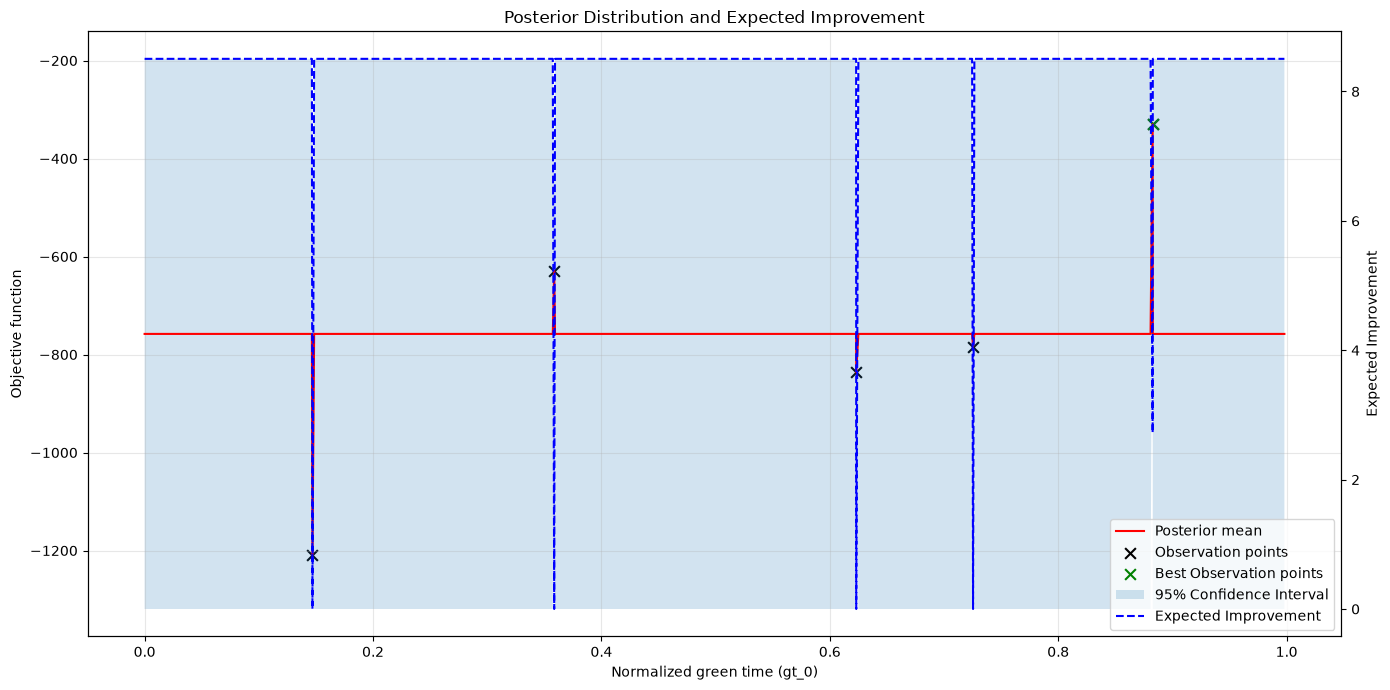

Prior lengthscale :
tensor([[0.1000]], dtype=torch.float64, grad_fn=<SoftplusBackward0>)
Prior outputscale :
tensor(0.7995, dtype=torch.float64, grad_fn=<SoftplusBackward0>)
Prior constant mean :
Parameter containing:
tensor(-5.6365e-15, dtype=torch.float64, requires_grad=True)
---------------------------------
Mean train y:
tensor(-757.8921, dtype=torch.float64)
Var train y:
tensor(102610.2928, dtype=torch.float64)
STD train y:
tensor(320.3284, dtype=torch.float64)
----------------------------------------
Prior outputscale on original scale:
tensor(82036.4222, dtype=torch.float64, grad_fn=<MulBackward0>)
Prior constant mean on original scale:
tensor(-757.8921, dtype=torch.float64, grad_fn=<AddBackward0>)


In [2]:
additional_xml_gt="./Ingolstadt Network/additional_gt.xml"
initial_tl_df=create_initial_tl_df(additional_xml_gt)
raw_samples=512
x_dim=98
lower_bounds=[5]*x_dim
upper_bounds=get_upper_bounds(initial_tl_df)
dtype=torch.double
x_bounds=torch.tensor(
    [lower_bounds,
    upper_bounds],
    dtype=dtype
)
initial_length_scale_value=0.1

bo_df=pd.read_csv("./BO_output/BO_df_VANILLA_iss_15_ls_0.1_dsf_3_restart0.csv")
bo_df_init=bo_df[:5]
train_X= torch.from_numpy(bo_df_init[[f"gt_{i}" for i in range(x_dim)]].values)
train_X_norm = normalize(train_X,x_bounds)
train_X_norm=train_X_norm.to(dtype)
train_Y = -torch.from_numpy(bo_df_init[["loss_estimate"]].values)
train_Y=train_Y.to(dtype)

best_y,best_y_index=torch.max(train_Y,dim=0)

best_x_norm=train_X_norm[best_y_index]

gp_model, gp_mll =initialize_gp_model(train_X=train_X_norm,train_Y=train_Y,initial_length_scale_value=initial_length_scale_value)
fit_gpytorch_mll(gp_mll)

sobol_engine=SobolEngine(dimension=x_dim)

X_test=sobol_engine.draw(raw_samples)
X_test=X_test.to(dtype)

X_test_all=torch.concat([train_X_norm,X_test],axis=0)

posterior=gp_model.posterior(X_test_all)

mean_posterior=posterior.mean.squeeze(1).detach().numpy()
var_posterior=posterior.variance.squeeze(1).detach().numpy()
std_posterior=posterior.variance.sqrt().squeeze(1).detach().numpy()

x = X_test_all[:, 0].numpy()

# Sort points according to gt_0

EI = LogExpectedImprovement(gp_model, best_f=best_y.item(), maximize=True)

acq_values=EI(X_test_all.unsqueeze(dim=1))
acq_values=acq_values.detach().cpu().numpy().flatten()

fig, ax1 = plt.subplots(figsize=(14, 7))

idx = np.argsort(x)
x = x[idx]
mean = mean_posterior[idx]
std = std_posterior[idx]
acq_values = acq_values[idx]


# Axe Y gauche : Posterior distribution
ax1.plot(x, mean, label="Posterior mean", color="red")

ax1.scatter(
    train_X_norm[:, 0].numpy(),
    train_Y.numpy().flatten(),
    marker='x',
    color='black',
    s=60,
    label="Observation points"
)

ax1.scatter(
    best_x_norm[:, 0].numpy(),
    best_y.numpy().flatten(),
    marker='x',
    color='green',
    s=60,
    label="Best Observation points"
)

ax1.fill_between(
    x,
    mean - 1.96 * std,
    mean + 1.96 * std,
    alpha=0.2,
    label="95% Confidence Interval"
)

ax1.set_xlabel("Normalized green time (gt_0)")
ax1.set_ylabel("Objective function")
ax1.grid(alpha=0.3)

# Axe Y droit : Expected Improvement
ax2 = ax1.twinx()

ax2.plot(
    x,
    np.exp(acq_values),
    color="blue",
    linestyle="--",
    label="Expected Improvement"
)

ax2.set_ylabel("Expected Improvement")

# Combiner les légendes des deux axes
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()

ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="best")

plt.title("Posterior Distribution and Expected Improvement")
plt.tight_layout()
plt.show()

print("Prior lengthscale :")
print(gp_model.covar_module.base_kernel.lengthscale)
print("Prior outputscale :")
print(gp_model.covar_module.outputscale)
print("Prior constant mean :")
print(gp_model.mean_module.constant)
print("---------------------------------")
print("Mean train y:")
print(train_Y.mean())
print("Var train y:")
print(train_Y.var())
print("STD train y:")
print(train_Y.std())
print("----------------------------------------")
print("Prior outputscale on original scale:")
print((gp_model.covar_module.outputscale)*train_Y.std()**2)
print("Prior constant mean on original scale:")
print(gp_model.mean_module.constant*train_Y.std()+train_Y.mean())

# Plot for the VANILLA scaled version iss 15

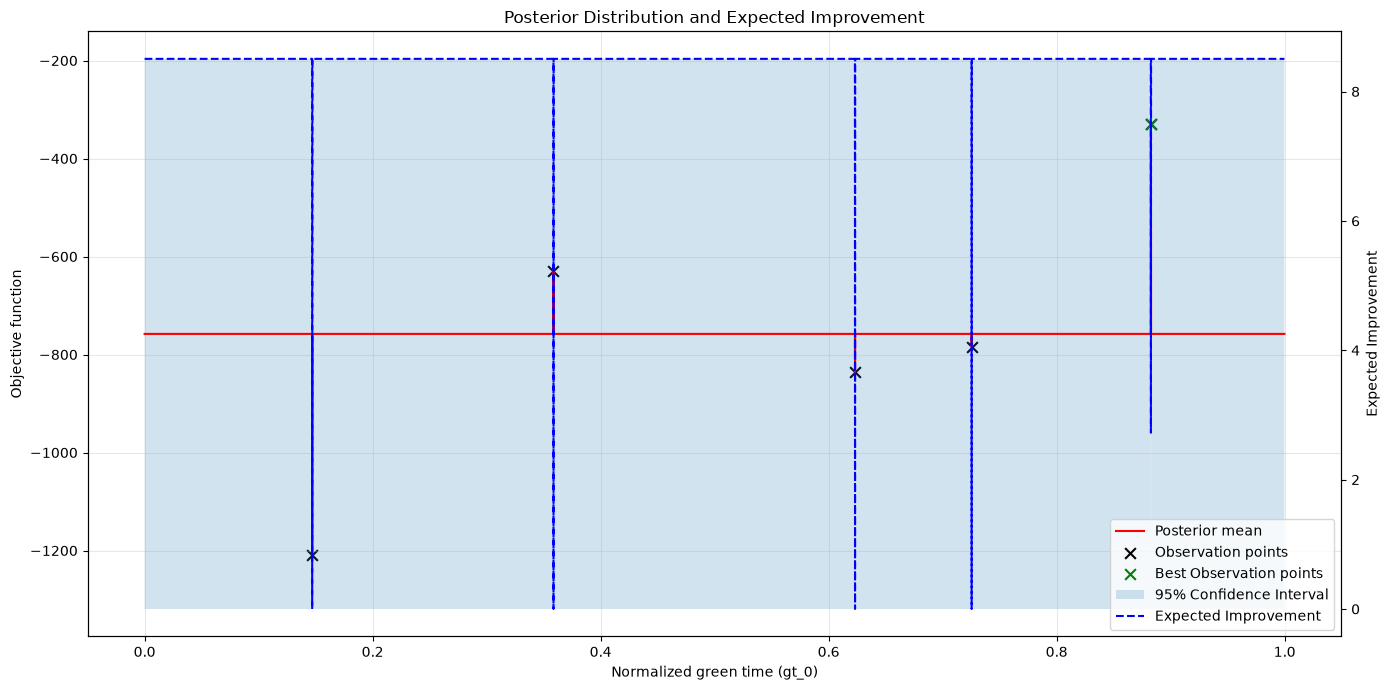

Prior lengthscale :
tensor([[0.3877]], dtype=torch.float64, grad_fn=<SoftplusBackward0>)
Prior outputscale :
tensor(0.7995, dtype=torch.float64, grad_fn=<SoftplusBackward0>)
Prior constant mean :
Parameter containing:
tensor(6.3101e-06, dtype=torch.float64, requires_grad=True)
---------------------------------
Mean train y:
tensor(-757.8921, dtype=torch.float64)
Var train y:
tensor(102610.2928, dtype=torch.float64)
STD train y:
tensor(320.3284, dtype=torch.float64)
----------------------------------------
Prior outputscale on original scale:
tensor(82037.5052, dtype=torch.float64, grad_fn=<MulBackward0>)
Prior constant mean on original scale:
tensor(-757.8901, dtype=torch.float64, grad_fn=<AddBackward0>)


In [10]:
additional_xml_gt="./Ingolstadt Network/additional_gt.xml"
initial_tl_df=create_initial_tl_df(additional_xml_gt)
raw_samples=min(100*x_dim,5000)
x_dim=98
lower_bounds=[5]*x_dim
upper_bounds=get_upper_bounds(initial_tl_df)
dtype=torch.double
x_bounds=torch.tensor(
    [lower_bounds,
    upper_bounds],
    dtype=dtype
)
initial_length_scale_value=0.1*np.sqrt(x_dim)

bo_df=pd.read_csv("./BO_output/BO_df_VANILLA_iss_15_ls_0.1scaled_dsf_3_restart0.csv")
bo_df_init=bo_df[:5]
train_X= torch.from_numpy(bo_df_init[[f"gt_{i}" for i in range(x_dim)]].values)
train_X_norm = normalize(train_X,x_bounds)
train_X_norm=train_X_norm.to(dtype)
train_Y = -torch.from_numpy(bo_df_init[["loss_estimate"]].values)
train_Y=train_Y.to(dtype)

best_y,best_y_index=torch.max(train_Y,dim=0)

best_x_norm=train_X_norm[best_y_index]

gp_model, gp_mll =initialize_gp_model(train_X=train_X_norm,train_Y=train_Y,initial_length_scale_value=initial_length_scale_value)
fit_gpytorch_mll(gp_mll)

sobol_engine=SobolEngine(dimension=x_dim)

X_test=sobol_engine.draw(raw_samples)
X_test=X_test.to(dtype)

X_test_all=torch.concat([train_X_norm,X_test],axis=0)

posterior=gp_model.posterior(X_test_all)

mean_posterior=posterior.mean.squeeze(1).detach().numpy()
var_posterior=posterior.variance.squeeze(1).detach().numpy()
std_posterior=posterior.variance.sqrt().squeeze(1).detach().numpy()

x = X_test_all[:, 0].numpy()

# Sort points according to gt_0

EI = LogExpectedImprovement(gp_model, best_f=best_y.item(), maximize=True)

acq_values=EI(X_test_all.unsqueeze(dim=1))
acq_values=acq_values.detach().cpu().numpy().flatten()

fig, ax1 = plt.subplots(figsize=(14, 7))

idx = np.argsort(x)
x = x[idx]
mean = mean_posterior[idx]
std = std_posterior[idx]
acq_values = acq_values[idx]


# Axe Y gauche : Posterior distribution
ax1.plot(x, mean, label="Posterior mean", color="red")

ax1.scatter(
    train_X_norm[:, 0].numpy(),
    train_Y.numpy().flatten(),
    marker='x',
    color='black',
    s=60,
    label="Observation points"
)

ax1.scatter(
    best_x_norm[:, 0].numpy(),
    best_y.numpy().flatten(),
    marker='x',
    color='green',
    s=60,
    label="Best Observation points"
)

ax1.fill_between(
    x,
    mean - 1.96 * std,
    mean + 1.96 * std,
    alpha=0.2,
    label="95% Confidence Interval"
)

ax1.set_xlabel("Normalized green time (gt_0)")
ax1.set_ylabel("Objective function")
ax1.grid(alpha=0.3)

# Axe Y droit : Expected Improvement
ax2 = ax1.twinx()

ax2.plot(
    x,
    np.exp(acq_values),
    color="blue",
    linestyle="--",
    label="Expected Improvement"
)

ax2.set_ylabel("Expected Improvement")

# Combiner les légendes des deux axes
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()

ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="best")

plt.title("Posterior Distribution and Expected Improvement")
plt.tight_layout()
plt.show()

print("Prior lengthscale :")
print(gp_model.covar_module.base_kernel.lengthscale)
print("Prior outputscale :")
print(gp_model.covar_module.outputscale)
print("Prior constant mean :")
print(gp_model.mean_module.constant)
print("---------------------------------")
print("Mean train y:")
print(train_Y.mean())
print("Var train y:")
print(train_Y.var())
print("STD train y:")
print(train_Y.std())
print("----------------------------------------")
print("Prior outputscale on original scale:")
print((gp_model.covar_module.outputscale)*train_Y.std()**2)
print("Prior constant mean on original scale:")
print(gp_model.mean_module.constant*train_Y.std()+train_Y.mean())

# Plot for the Vanilla version iss 15 default

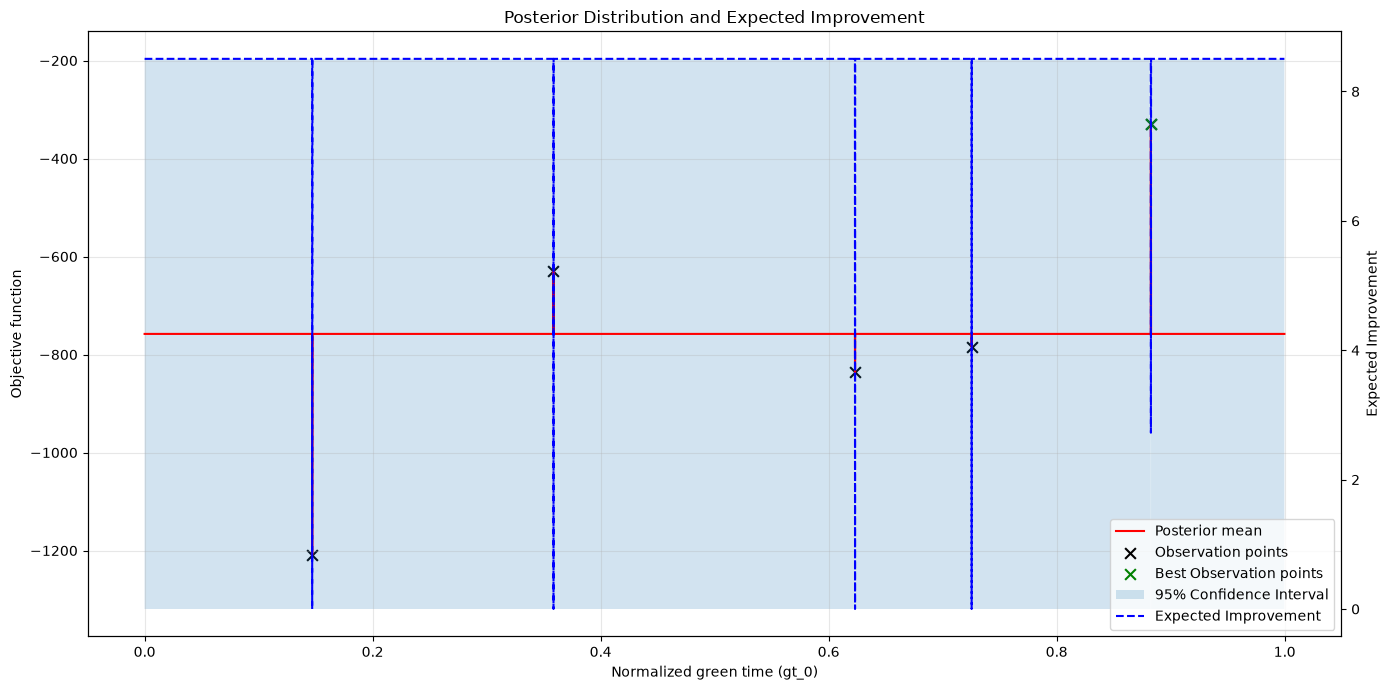

Prior lengthscale :
tensor([[0.4120]], dtype=torch.float64, grad_fn=<SoftplusBackward0>)
Prior outputscale :
tensor(0.7995, dtype=torch.float64, grad_fn=<SoftplusBackward0>)
Prior constant mean :
Parameter containing:
tensor(-3.6520e-06, dtype=torch.float64, requires_grad=True)
---------------------------------
Mean train y:
tensor(-757.8921, dtype=torch.float64)
Var train y:
tensor(102610.2928, dtype=torch.float64)
STD train y:
tensor(320.3284, dtype=torch.float64)
----------------------------------------
Prior outputscale on original scale:
tensor(82036.1918, dtype=torch.float64, grad_fn=<MulBackward0>)
Prior constant mean on original scale:
tensor(-757.8933, dtype=torch.float64, grad_fn=<AddBackward0>)


In [9]:
additional_xml_gt="./Ingolstadt Network/additional_gt.xml"
initial_tl_df=create_initial_tl_df(additional_xml_gt)
raw_samples=min(100*x_dim,5000)
x_dim=98
lower_bounds=[5]*x_dim
upper_bounds=get_upper_bounds(initial_tl_df)
dtype=torch.double
x_bounds=torch.tensor(
    [lower_bounds,
    upper_bounds],
    dtype=dtype
)
initial_length_scale_value=0.6931

bo_df=pd.read_csv("./BO_output/BO_df_VANILLA_iss_15_ls_0.6931_dsf_3_restart0.csv")
bo_df_init=bo_df[:5]
train_X= torch.from_numpy(bo_df_init[[f"gt_{i}" for i in range(x_dim)]].values)
train_X_norm = normalize(train_X,x_bounds)
train_X_norm=train_X_norm.to(dtype)
train_Y = -torch.from_numpy(bo_df_init[["loss_estimate"]].values)
train_Y=train_Y.to(dtype)

best_y,best_y_index=torch.max(train_Y,dim=0)

best_x_norm=train_X_norm[best_y_index]

gp_model, gp_mll =initialize_gp_model(train_X=train_X_norm,train_Y=train_Y,initial_length_scale_value=initial_length_scale_value)
fit_gpytorch_mll(gp_mll)

sobol_engine=SobolEngine(dimension=x_dim)

X_test=sobol_engine.draw(raw_samples)
X_test=X_test.to(dtype)

X_test_all=torch.concat([train_X_norm,X_test],axis=0)

posterior=gp_model.posterior(X_test_all)

mean_posterior=posterior.mean.squeeze(1).detach().numpy()
var_posterior=posterior.variance.squeeze(1).detach().numpy()
std_posterior=posterior.variance.sqrt().squeeze(1).detach().numpy()

x = X_test_all[:, 0].numpy()

# Sort points according to gt_0

EI = LogExpectedImprovement(gp_model, best_f=best_y.item(), maximize=True)

acq_values=EI(X_test_all.unsqueeze(dim=1))
acq_values=acq_values.detach().cpu().numpy().flatten()

fig, ax1 = plt.subplots(figsize=(14, 7))

idx = np.argsort(x)
x = x[idx]
mean = mean_posterior[idx]
std = std_posterior[idx]
acq_values = acq_values[idx]


# Axe Y gauche : Posterior distribution
ax1.plot(x, mean, label="Posterior mean", color="red")

ax1.scatter(
    train_X_norm[:, 0].numpy(),
    train_Y.numpy().flatten(),
    marker='x',
    color='black',
    s=60,
    label="Observation points"
)

ax1.scatter(
    best_x_norm[:, 0].numpy(),
    best_y.numpy().flatten(),
    marker='x',
    color='green',
    s=60,
    label="Best Observation points"
)

ax1.fill_between(
    x,
    mean - 1.96 * std,
    mean + 1.96 * std,
    alpha=0.2,
    label="95% Confidence Interval"
)

ax1.set_xlabel("Normalized green time (gt_0)")
ax1.set_ylabel("Objective function")
ax1.grid(alpha=0.3)

# Axe Y droit : Expected Improvement
ax2 = ax1.twinx()

ax2.plot(
    x,
    np.exp(acq_values),
    color="blue",
    linestyle="--",
    label="Expected Improvement"
)

ax2.set_ylabel("Expected Improvement")

# Combiner les légendes des deux axes
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()

ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="best")

plt.title("Posterior Distribution and Expected Improvement")
plt.tight_layout()
plt.show()

print("Prior lengthscale :")
print(gp_model.covar_module.base_kernel.lengthscale)
print("Prior outputscale :")
print(gp_model.covar_module.outputscale)
print("Prior constant mean :")
print(gp_model.mean_module.constant)
print("---------------------------------")
print("Mean train y:")
print(train_Y.mean())
print("Var train y:")
print(train_Y.var())
print("STD train y:")
print(train_Y.std())
print("----------------------------------------")
print("Prior outputscale on original scale:")
print((gp_model.covar_module.outputscale)*train_Y.std()**2)
print("Prior constant mean on original scale:")
print(gp_model.mean_module.constant*train_Y.std()+train_Y.mean())

# Plot for the MSR version iss 15

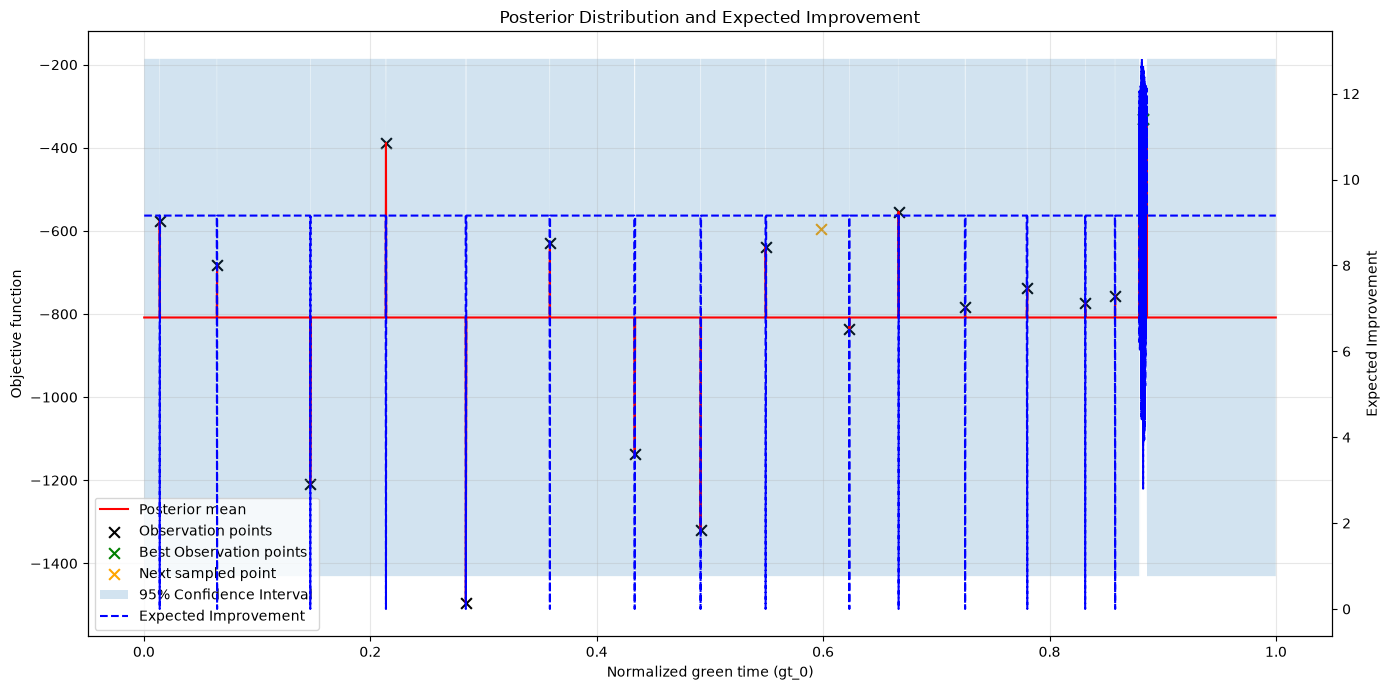

Prior lengthscale :
tensor([[0.1376]], dtype=torch.float64, grad_fn=<SoftplusBackward0>)
Prior outputscale :
tensor(0.9366, dtype=torch.float64, grad_fn=<SoftplusBackward0>)
Prior constant mean :
Parameter containing:
tensor(-0.0165, dtype=torch.float64, requires_grad=True)
---------------------------------
Mean train y:
tensor(-802.9737, dtype=torch.float64)
Var train y:
tensor(107647.3167, dtype=torch.float64)
STD train y:
tensor(328.0965, dtype=torch.float64)
----------------------------------------
Prior outputscale on original scale:
tensor(100826.1164, dtype=torch.float64, grad_fn=<MulBackward0>)
Prior constant mean on original scale:
tensor(-808.3941, dtype=torch.float64, grad_fn=<AddBackward0>)


Text(0.5, 1.0, 'Distribution of the Posterior variance values')

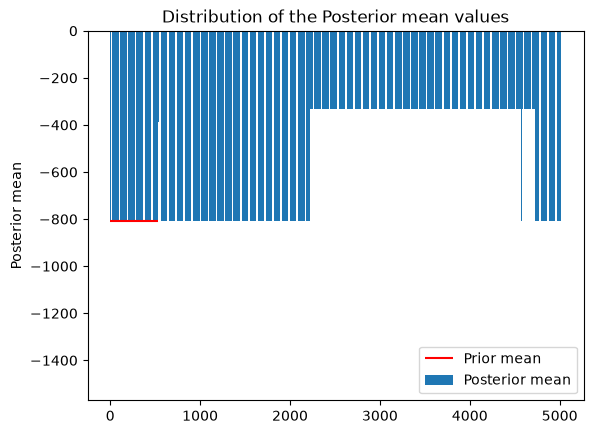

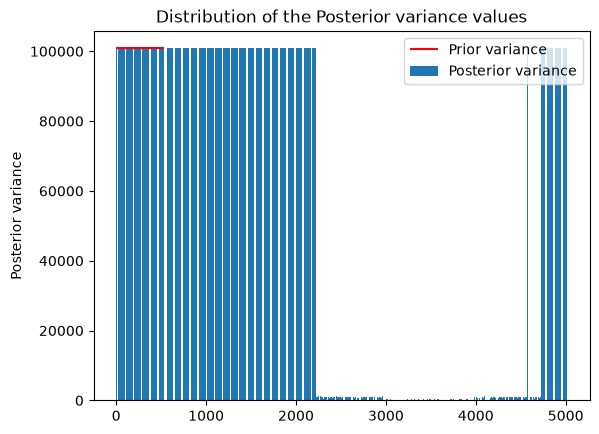

In [8]:
additional_xml_gt="./Ingolstadt Network/additional_gt.xml"
initial_tl_df=create_initial_tl_df(additional_xml_gt)

x_dim=98
raw_samples=min(100*x_dim,5000)
raasp_sampler=RAASP_sampler(x_dim)
lower_bounds=[5]*x_dim
upper_bounds=get_upper_bounds(initial_tl_df)
dtype=torch.double
x_bounds=torch.tensor(
    [lower_bounds,
    upper_bounds],
    dtype=dtype
)
initial_length_scale_value=0.1*np.sqrt(x_dim)

bo_df=pd.read_csv("./BO_output/BO_df_MSR_iss_15_ls_0.1scaled_dsf_3_restart0.csv")
i=16
bo_df_init=bo_df[:i]

next_sampled_point=normalize(torch.from_numpy(bo_df.iloc[i][[f"gt_{i}" for i in range(x_dim)]].values.reshape(1,-1)),x_bounds)
next_y=-bo_df.iloc[i]["loss_estimate"]

train_X= torch.from_numpy(bo_df_init[[f"gt_{i}" for i in range(x_dim)]].values)
train_X_norm = normalize(train_X,x_bounds)
train_X_norm=train_X_norm.to(dtype)
train_Y = -torch.from_numpy(bo_df_init[["loss_estimate"]].values)
train_Y=train_Y.to(dtype)

best_y,best_y_index=torch.max(train_Y,dim=0)
best_x_norm=train_X_norm[best_y_index]

gp_model, gp_mll =initialize_gp_model(train_X=train_X_norm,train_Y=train_Y,initial_length_scale_value=initial_length_scale_value)
fit_gpytorch_mll(gp_mll)

top_df=bo_df_init.copy()
n_obs=len(top_df)
top_df=top_df.nsmallest(int(np.ceil((5/100)*n_obs)),columns="loss_estimate")
top_x=torch.from_numpy(top_df[[f"gt_{i}" for i in range(x_dim)]].values)
top_x_norm=normalize(top_x,x_bounds)
top_y=-torch.tensor(top_df["loss_estimate"].values)


X_test=raasp_sampler.RAASP_generator(top_x=top_x_norm,raw_samples=raw_samples)

X_test_all=torch.concat([train_X_norm,X_test],axis=0)

posterior=gp_model.posterior(X_test_all)


mean_posterior=posterior.mean.squeeze(1).detach().numpy()
var_posterior=posterior.variance.squeeze(1).detach().numpy()
std_posterior=posterior.variance.sqrt().squeeze(1).detach().numpy()

x = X_test_all[:, 0].numpy()

# Sort points according to gt_0
idx = np.argsort(x)
x = x[idx]
mean = mean_posterior[idx]
var=var_posterior[idx]
std = std_posterior[idx]

EI = LogExpectedImprovement(gp_model, best_f=best_y.item(), maximize=True)
acq_values=EI(X_test_all.unsqueeze(dim=1))
acq_values=acq_values.detach().cpu().numpy().flatten()
acq_values = acq_values[idx]


fig, ax1 = plt.subplots(figsize=(14, 7))

# Axe Y gauche : Posterior distribution
ax1.plot(x, mean, label="Posterior mean", color="red")

ax1.scatter(
    train_X_norm[:, 0].numpy(),
    train_Y.numpy().flatten(),
    marker='x',
    color='black',
    s=60,
    label="Observation points"
)

ax1.scatter(
    top_x_norm[:, 0].numpy(),
    top_y.numpy().flatten(),
    marker='x',
    color='green',
    s=60,
    label="Best Observation points"
)

ax1.scatter(
    next_sampled_point[:, 0].numpy(),
    next_y,
    marker='x',
    color='orange',
    s=60,
    label="Next sampled point"
)


ax1.fill_between(
    x,
    mean - 1.96 * std,
    mean + 1.96 * std,
    alpha=0.2,
    label="95% Confidence Interval"
)

ax1.set_xlabel("Normalized green time (gt_0)")
ax1.set_ylabel("Objective function")
ax1.grid(alpha=0.3)

# Axe Y droit : Expected Improvement

ax2 = ax1.twinx()

ax2.plot(
    x,
    np.exp(acq_values),
    color="blue",
    linestyle="--",
    label="Expected Improvement"
)

ax2.set_ylabel("Expected Improvement")

# Combiner les légendes des deux axes
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()

ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="best")

#plt.xlim(0.5, 0.8)
plt.title("Posterior Distribution and Expected Improvement")
plt.tight_layout()
plt.show()

print("Prior lengthscale :")
print(gp_model.covar_module.base_kernel.lengthscale)
print("Prior outputscale :")
print(gp_model.covar_module.outputscale)
print("Prior constant mean :")
print(gp_model.mean_module.constant)
print("---------------------------------")
print("Mean train y:")
print(train_Y.mean())
print("Var train y:")
print(train_Y.var())
print("STD train y:")
print(train_Y.std())
print("----------------------------------------")
print("Prior outputscale on original scale:")
print((gp_model.covar_module.outputscale)*train_Y.std()**2)
print("Prior constant mean on original scale:")
print(gp_model.mean_module.constant*train_Y.std()+train_Y.mean())

plt.figure()
plt.bar(np.arange(len(mean)),mean,label="Posterior mean")
plt.hlines(y=(gp_model.mean_module.constant*train_Y.std()+train_Y.mean()).detach().numpy(),color="red",xmin=0,xmax=527,label="Prior mean")
plt.ylabel("Posterior mean")
plt.legend()
plt.title("Distribution of the Posterior mean values")

plt.figure()
plt.bar(np.arange(len(var)),var,label="Posterior variance")
plt.hlines(y=((gp_model.covar_module.outputscale)*train_Y.std()**2).detach().numpy(),color="red",xmin=0,xmax=527,label="Prior variance")
plt.ylabel("Posterior variance")
plt.legend()
plt.title("Distribution of the Posterior variance values")

# Plot for the Turbo-1 version iss 15

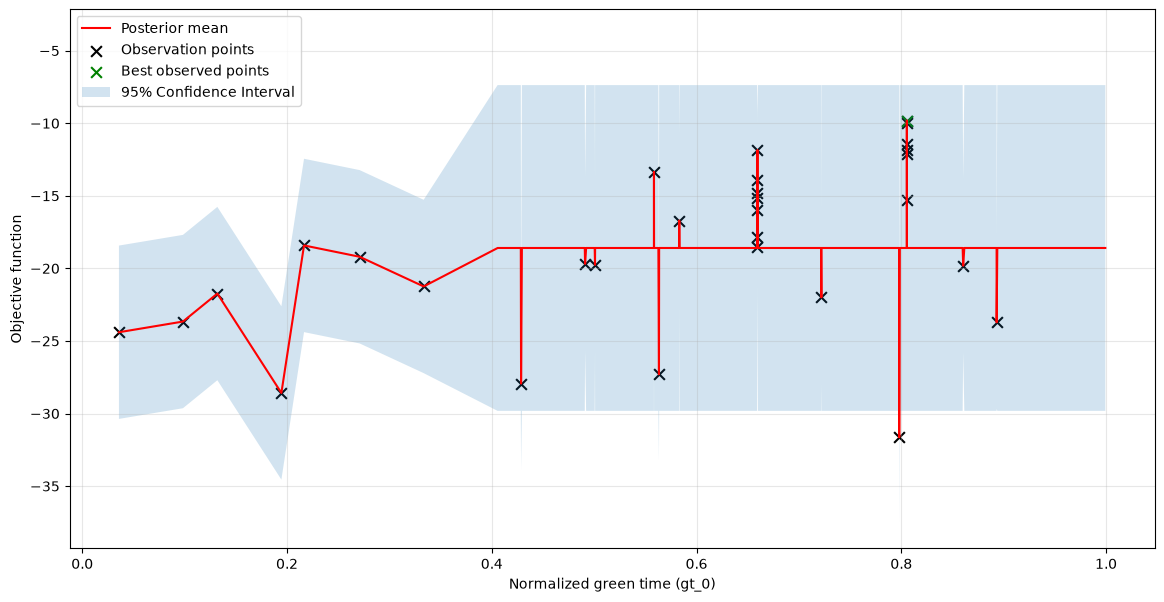

tr lb :
tensor([0.4054, 0.0744, 0.1585, 0.0000, 0.1137, 0.0000, 0.4874, 0.2329, 0.0468,
        0.3801, 0.0000, 0.0000, 0.0000, 0.4258, 0.2064, 0.0175, 0.5928, 0.4425,
        0.3455, 0.3107, 0.0012, 0.4348, 0.5127, 0.0000, 0.3103, 0.2093, 0.0000,
        0.0000, 0.0000, 0.5560, 0.1161, 0.0000, 0.3079, 0.2257, 0.2887, 0.0000,
        0.0000, 0.1683, 0.0000, 0.5171, 0.0000, 0.0000, 0.1717, 0.3575, 0.5227,
        0.1783, 0.0000, 0.1998, 0.0000, 0.1474, 0.0257, 0.0449, 0.0000, 0.1312,
        0.0000, 0.0000, 0.1918, 0.5138, 0.0166, 0.0000, 0.4456, 0.2735, 0.0000,
        0.0000, 0.5795, 0.1103, 0.0000, 0.1819, 0.0000, 0.5441, 0.0000, 0.4753,
        0.0000, 0.3361, 0.0000, 0.3026, 0.0000, 0.1820, 0.0221, 0.0000, 0.2958,
        0.5042, 0.5598, 0.1675, 0.0000, 0.0000, 0.3443, 0.4126, 0.3076, 0.0000,
        0.0000, 0.5794, 0.3609, 0.0000, 0.0000, 0.3736, 0.2598, 0.2837],
       dtype=torch.float64)
tr ub :
tensor([1.0000, 0.8744, 0.9585, 0.6672, 0.9137, 0.6855, 1.0000, 1.0000, 0.8468,
   

Text(0.5, 1.0, 'Distribution of the Posterior variance values')

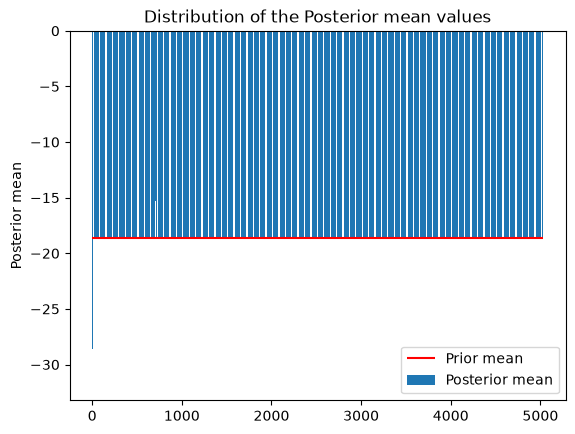

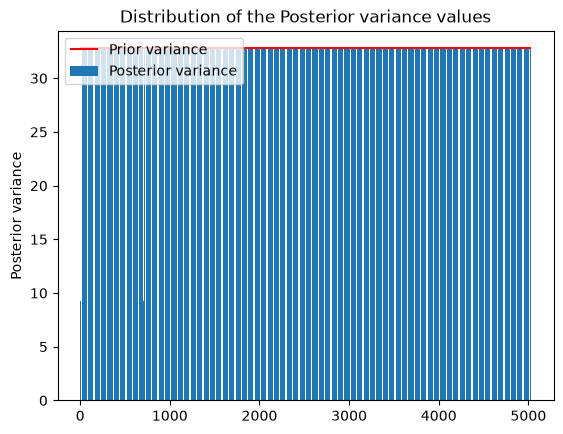

In [158]:
additional_xml_gt="./Ingolstadt Network/additional_gt.xml"
initial_tl_df=create_initial_tl_df(additional_xml_gt)
raw_samples=512


x_dim=98
tr_length=0.8
tr_candidates_generator=TRCandidatesGeneration(x_dim)
lower_bounds=[5]*x_dim
upper_bounds=get_upper_bounds(initial_tl_df)
dtype=torch.double
x_bounds=torch.tensor(
    [lower_bounds,
    upper_bounds],
    dtype=dtype
)
initial_length_scale_value=0.1

bo_df=pd.read_csv("./turbo_output/turbo_tr_0_iss_15_ls_0.1_rs_0_training.csv")
bo_df_init=bo_df[:30]
train_X= torch.from_numpy(bo_df_init[[f"gt_{i}" for i in range(x_dim)]].values)
train_X_norm = normalize(train_X,x_bounds)
train_X_norm=train_X_norm.to(dtype)
train_Y = -torch.from_numpy(bo_df_init[["loss_estimate"]].values)
train_Y=train_Y.to(dtype)

gp_model, gp_mll =initialize_gp_model(train_X=train_X_norm,train_Y=train_Y,initial_length_scale_value=initial_length_scale_value)

tr_x_norm=train_X_norm
tr_y=train_Y
tr_y_best,tr_y_best_idx=torch.max(tr_y,dim=0)
tr_x_best_norm=tr_x_norm[tr_y_best_idx.item()].clone().detach()
tr_ub=torch.clamp(tr_x_best_norm+tr_length/2,0.0,1.0)
tr_lb=torch.clamp(tr_x_best_norm-tr_length/2,0.0,1.0)


X_test=tr_candidates_generator.RAASP_sampling(
                            tr_x_best_norm,
                            tr_lb,
                            tr_ub
                            )


X_test_all=torch.concat([train_X_norm,X_test],axis=0)

posterior=gp_model.posterior(X_test_all)
fit_gpytorch_mll(gp_mll)


mean_posterior=posterior.mean.squeeze(1).detach().numpy()
var_posterior=posterior.variance.squeeze(1).detach().numpy()
std_posterior=posterior.variance.sqrt().squeeze(1).detach().numpy()

x = X_test_all[:, 0].numpy()


# Sort points according to gt_0
idx = np.argsort(x)

x = x[idx]
mean = mean_posterior[idx]
std = std_posterior[idx]
var=var_posterior[idx]

plt.figure(figsize=(14, 7))

plt.plot(x, mean, label="Posterior mean", color="red")

plt.scatter(
    train_X_norm[:, 0].numpy(),
    train_Y.numpy().flatten(),
    marker='x',
    color='black',
    s=60,
    label="Observation points"
)

plt.scatter(
    tr_x_best_norm.unsqueeze(0)[:, 0].numpy(),
    tr_y_best.numpy().flatten(),
    marker='x',
    color='green',
    s=60,
    label="Best observed points"
)

plt.fill_between(
    x,
    mean - 1.96 * std,
    mean + 1.96 * std,
    alpha=0.2,
    label="95% Confidence Interval"
)

plt.xlabel("Normalized green time (gt_0)")
plt.ylabel("Objective function")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("tr lb :")
print(tr_lb)
print("tr ub :")
print(tr_ub)
print("------------------------------")
print("Prior lengthscale :")
print(gp_model.covar_module.base_kernel.lengthscale)
print("Prior outputscale :")
print(gp_model.covar_module.outputscale)
print("Prior constant mean :")
print(gp_model.mean_module.constant)
print("---------------------------------")
print("Mean train y:")
print(train_Y.mean())
print("Var train y:")
print(train_Y.var())
print("STD train y:")
print(train_Y.std())
print("----------------------------------------")
print("Prior outputscale on original scale:")
print((gp_model.covar_module.outputscale)*train_Y.std()**2)
print("Prior constant mean on original scale:")
print(gp_model.mean_module.constant*train_Y.std()+train_Y.mean())

plt.figure()
plt.bar(np.arange(len(mean)),mean,label="Posterior mean")
plt.hlines(y=(gp_model.mean_module.constant*train_Y.std()+train_Y.mean()).detach().numpy(),color="red",xmin=0,xmax=len(mean),label="Prior mean")
plt.ylabel("Posterior mean")
plt.legend()
plt.title("Distribution of the Posterior mean values")

plt.figure()
plt.bar(np.arange(len(var)),var,label="Posterior variance")
plt.hlines(y=((gp_model.covar_module.outputscale)*train_Y.std()**2).detach().numpy(),color="red",xmin=0,xmax=len(var),label="Prior variance")
plt.ylabel("Posterior variance")
plt.legend()
plt.title("Distribution of the Posterior variance values")

# Plot for the Turbo-1 Scaled version iss 15 

c:\Users\sh032\anaconda3\envs\thesis\Lib\site-packages\gpytorch\distributions\multivariate_normal.py:376: NumericalWarning: Negative variance values detected. This is likely due to numerical instabilities. Rounding negative variances up to 1e-10.
  warnings.warn(


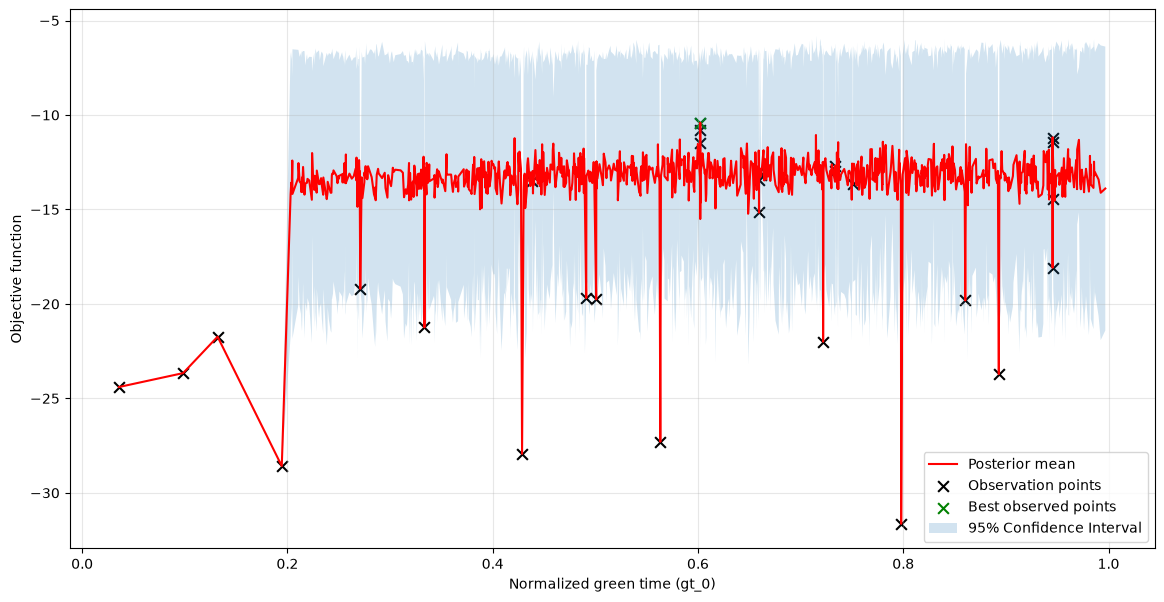

tr lb :
tensor([0.2022, 0.4462, 0.0000, 0.2638, 0.2087, 0.5526, 0.1054, 0.0140, 0.0000,
        0.3631, 0.0000, 0.0473, 0.2237, 0.4258, 0.1735, 0.0000, 0.4381, 0.1578,
        0.1297, 0.0000, 0.0000, 0.2201, 0.5127, 0.0000, 0.0188, 0.4995, 0.1479,
        0.0000, 0.0618, 0.0896, 0.0000, 0.0000, 0.1062, 0.0283, 0.4377, 0.0000,
        0.0000, 0.5380, 0.3294, 0.0794, 0.0000, 0.0000, 0.1717, 0.0000, 0.5227,
        0.2301, 0.0000, 0.4449, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.5523,
        0.0462, 0.0000, 0.3545, 0.2917, 0.3216, 0.0000, 0.4962, 0.4779, 0.2905,
        0.0000, 0.5472, 0.4526, 0.0000, 0.0703, 0.0000, 0.4196, 0.1559, 0.2896,
        0.0000, 0.5905, 0.0000, 0.0000, 0.1405, 0.3284, 0.0188, 0.3683, 0.0000,
        0.5948, 0.4278, 0.1775, 0.0517, 0.0092, 0.0507, 0.2195, 0.2104, 0.0000,
        0.0000, 0.4068, 0.4279, 0.0000, 0.3525, 0.2589, 0.4847, 0.0000],
       dtype=torch.float64)
tr ub :
tensor([1.0000, 1.0000, 0.5606, 1.0000, 1.0000, 1.0000, 0.9054, 0.8140, 0.6298,
   

Text(0.5, 1.0, 'Distribution of the Posterior variance values')

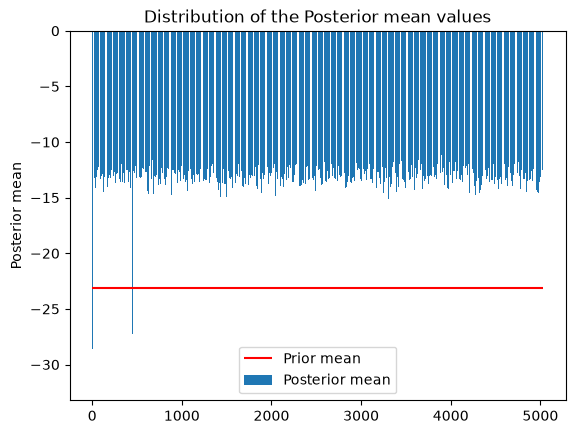

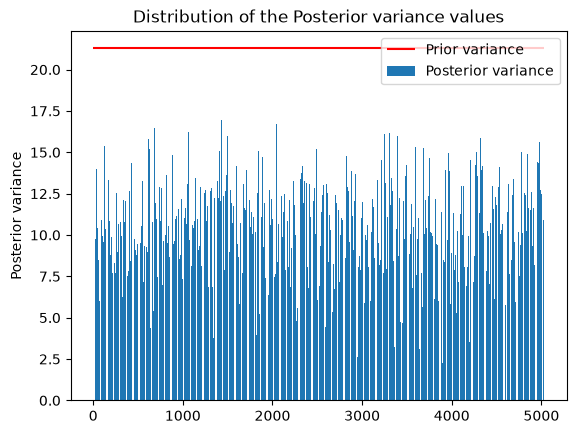

In [160]:
additional_xml_gt="./Ingolstadt Network/additional_gt.xml"
initial_tl_df=create_initial_tl_df(additional_xml_gt)
raw_samples=512


x_dim=98
tr_length=0.8
tr_candidates_generator=TRCandidatesGeneration(x_dim)
lower_bounds=[5]*x_dim
upper_bounds=get_upper_bounds(initial_tl_df)
dtype=torch.double
x_bounds=torch.tensor(
    [lower_bounds,
    upper_bounds],
    dtype=dtype
)
initial_length_scale_value=0.1*np.sqrt(x_dim)

bo_df=pd.read_csv("./turbo_output/turbo_tr_0_iss_15_ls_0.1scaled_rs_0_training.csv")
bo_df_init=bo_df[:30]
train_X= torch.from_numpy(bo_df_init[[f"gt_{i}" for i in range(x_dim)]].values)
train_X_norm = normalize(train_X,x_bounds)
train_X_norm=train_X_norm.to(dtype)
train_Y = -torch.from_numpy(bo_df_init[["loss_estimate"]].values)
train_Y=train_Y.to(dtype)

gp_model, gp_mll =initialize_gp_model(train_X=train_X_norm,train_Y=train_Y,initial_length_scale_value=initial_length_scale_value)

tr_x_norm=train_X_norm
tr_y=train_Y
tr_y_best,tr_y_best_idx=torch.max(tr_y,dim=0)
tr_x_best_norm=tr_x_norm[tr_y_best_idx.item()].clone().detach()
tr_ub=torch.clamp(tr_x_best_norm+tr_length/2,0.0,1.0)
tr_lb=torch.clamp(tr_x_best_norm-tr_length/2,0.0,1.0)


X_test=tr_candidates_generator.RAASP_sampling(
                            tr_x_best_norm,
                            tr_lb,
                            tr_ub
                            )


X_test_all=torch.concat([train_X_norm,X_test],axis=0)

posterior=gp_model.posterior(X_test_all)
fit_gpytorch_mll(gp_mll)


mean_posterior=posterior.mean.squeeze(1).detach().numpy()
var_posterior=posterior.variance.squeeze(1).detach().numpy()
std_posterior=posterior.variance.sqrt().squeeze(1).detach().numpy()

x = X_test_all[:, 0].numpy()


# Sort points according to gt_0
idx = np.argsort(x)

x = x[idx]
mean = mean_posterior[idx]
std = std_posterior[idx]
var=var_posterior[idx]


plt.figure(figsize=(14, 7))

plt.plot(x, mean, label="Posterior mean", color="red")

plt.scatter(
    train_X_norm[:, 0].numpy(),
    train_Y.numpy().flatten(),
    marker='x',
    color='black',
    s=60,
    label="Observation points"
)

plt.scatter(
    tr_x_best_norm.unsqueeze(0)[:, 0].numpy(),
    tr_y_best.numpy().flatten(),
    marker='x',
    color='green',
    s=60,
    label="Best observed points"
)

plt.fill_between(
    x,
    mean - 1.96 * std,
    mean + 1.96 * std,
    alpha=0.2,
    label="95% Confidence Interval"
)

plt.xlabel("Normalized green time (gt_0)")
plt.ylabel("Objective function")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("tr lb :")
print(tr_lb)
print("tr ub :")
print(tr_ub)
print("------------------------------")
print("Prior lengthscale :")
print(gp_model.covar_module.base_kernel.lengthscale)
print("Prior outputscale :")
print(gp_model.covar_module.outputscale)
print("Prior constant mean :")
print(gp_model.mean_module.constant)
print("---------------------------------")
print("Mean train y:")
print(train_Y.mean())
print("Var train y:")
print(train_Y.var())
print("STD train y:")
print(train_Y.std())
print("----------------------------------------")
print("Prior outputscale on original scale:")
print((gp_model.covar_module.outputscale)*train_Y.std()**2)
print("Prior constant mean on original scale:")
print(gp_model.mean_module.constant*train_Y.std()+train_Y.mean())



plt.figure()
plt.bar(np.arange(len(mean)),mean,label="Posterior mean")
plt.hlines(y=(gp_model.mean_module.constant*train_Y.std()+train_Y.mean()).detach().numpy(),color="red",xmin=0,xmax=len(mean),label="Prior mean")
plt.ylabel("Posterior mean")
plt.legend()
plt.title("Distribution of the Posterior mean values")

plt.figure()
plt.bar(np.arange(len(var)),var,label="Posterior variance")
plt.hlines(y=((gp_model.covar_module.outputscale)*train_Y.std()**2).detach().numpy(),color="red",xmin=0,xmax=len(var),label="Prior variance")
plt.ylabel("Posterior variance")
plt.legend()
plt.title("Distribution of the Posterior variance values")

# Plot for the Turbo-m version iss 15

# TR 0

(24, 101)


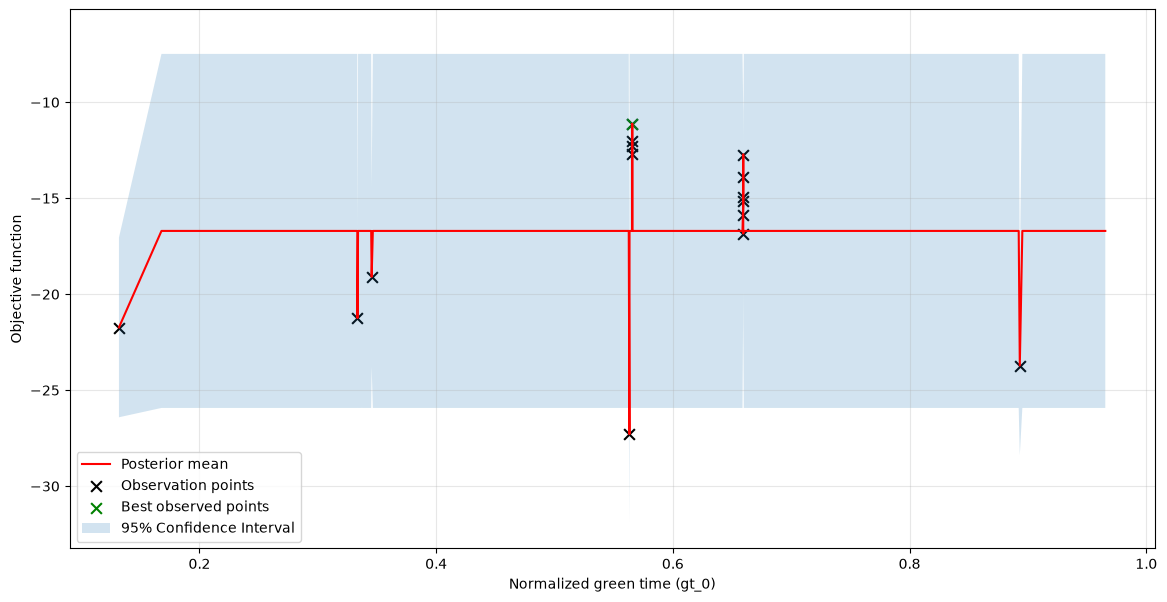

tr lb :
tensor([0.1657, 0.0000, 0.2592, 0.0000, 0.0000, 0.0000, 0.3186, 0.3083, 0.0000,
        0.0000, 0.1446, 0.0000, 0.1546, 0.4258, 0.3163, 0.1317, 0.5463, 0.2480,
        0.3077, 0.3578, 0.0000, 0.1420, 0.1743, 0.0000, 0.0000, 0.0500, 0.1479,
        0.0000, 0.0618, 0.5560, 0.0000, 0.0158, 0.1761, 0.0000, 0.4831, 0.0000,
        0.0449, 0.4703, 0.0000, 0.0000, 0.0000, 0.0808, 0.0014, 0.2696, 0.3977,
        0.1783, 0.0000, 0.3716, 0.0000, 0.1474, 0.0304, 0.0000, 0.0000, 0.4936,
        0.0000, 0.0000, 0.4683, 0.1397, 0.2255, 0.0912, 0.0000, 0.0000, 0.0000,
        0.0000, 0.5472, 0.5212, 0.0000, 0.1819, 0.0000, 0.0576, 0.2941, 0.5414,
        0.4566, 0.0000, 0.1507, 0.3026, 0.0000, 0.1786, 0.0000, 0.1107, 0.1010,
        0.3994, 0.5598, 0.1453, 0.4634, 0.0000, 0.5563, 0.4293, 0.2029, 0.0000,
        0.0000, 0.3423, 0.4305, 0.0000, 0.1384, 0.1652, 0.5061, 0.0233],
       dtype=torch.float64)
tr ub :
tensor([0.9657, 0.6829, 1.0000, 0.6672, 0.7446, 0.6855, 1.0000, 1.0000, 0.7964,
   

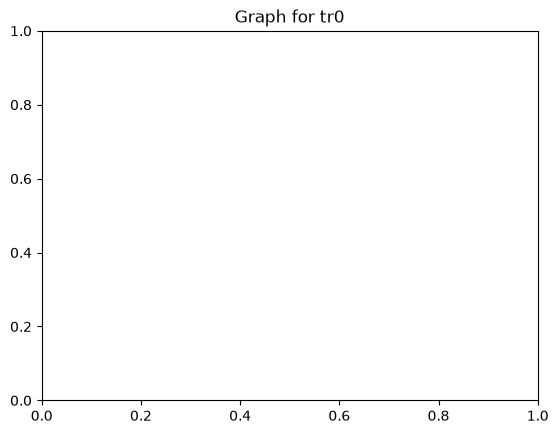

In [ ]:
additional_xml_gt="./Ingolstadt Network/additional_gt.xml"
initial_tl_df=create_initial_tl_df(additional_xml_gt)
raw_samples=512


x_dim=98
tr_length=0.8
tr_candidates_generator=TRCandidatesGeneration(x_dim)
lower_bounds=[5]*x_dim
upper_bounds=get_upper_bounds(initial_tl_df)
dtype=torch.double
x_bounds=torch.tensor(
    [lower_bounds,
    upper_bounds],
    dtype=dtype
)
initial_length_scale_value=0.1

bo_df=pd.read_csv("./turbo_output/turbo_tr_0_iss_15_ls_0.1_tr3_q1_rs_0_training.csv")
print(bo_df.shape)
bo_df_init=bo_df[:15]
train_X= torch.from_numpy(bo_df_init[[f"gt_{i}" for i in range(x_dim)]].values)
train_X_norm = normalize(train_X,x_bounds)
train_X_norm=train_X_norm.to(dtype)
train_Y = -torch.from_numpy(bo_df_init[["loss_estimate"]].values)
train_Y=train_Y.to(dtype)

gp_model, gp_mll =initialize_gp_model(train_X=train_X_norm,train_Y=train_Y,initial_length_scale_value=initial_length_scale_value)

tr_x_norm=train_X_norm
tr_y=train_Y
tr_y_best,tr_y_best_idx=torch.max(tr_y,dim=0)
tr_x_best_norm=tr_x_norm[tr_y_best_idx.item()].clone().detach()
tr_ub=torch.clamp(tr_x_best_norm+tr_length/2,0.0,1.0)
tr_lb=torch.clamp(tr_x_best_norm-tr_length/2,0.0,1.0)


X_test=tr_candidates_generator.RAASP_sampling(
                            tr_x_best_norm,
                            tr_lb,
                            tr_ub
                            )


X_test_all=torch.concat([train_X_norm,X_test],axis=0)

posterior=gp_model.posterior(X_test_all)
fit_gpytorch_mll(gp_mll)


mean_posterior=posterior.mean.squeeze(1).detach().numpy()
var_posterior=posterior.variance.squeeze(1).detach().numpy()
std_posterior=posterior.variance.sqrt().squeeze(1).detach().numpy()

x = X_test_all[:, 0].numpy()


# Sort points according to gt_0
idx = np.argsort(x)

x = x[idx]
mean = mean_posterior[idx]
std = std_posterior[idx]

plt.figure(figsize=(14, 7))

plt.plot(x, mean, label="Posterior mean", color="red")

plt.scatter(
    train_X_norm[:, 0].numpy(),
    train_Y.numpy().flatten(),
    marker='x',
    color='black',
    s=60,
    label="Observation points"
)

plt.scatter(
    tr_x_best_norm.unsqueeze(0)[:, 0].numpy(),
    tr_y_best.numpy().flatten(),
    marker='x',
    color='green',
    s=60,
    label="Best observed points"
)

plt.fill_between(
    x,
    mean - 1.96 * std,
    mean + 1.96 * std,
    alpha=0.2,
    label="95% Confidence Interval"
)

plt.xlabel("Normalized green time (gt_0)")
plt.ylabel("Objective function")
plt.legend()
plt.grid(alpha=0.3)
plt.title("Graph for tr0")
plt.show()

print("tr lb :")
print(tr_lb)
print("tr ub :")
print(tr_ub)
print("------------------------------")
print("Prior lengthscale :")
print(gp_model.covar_module.base_kernel.lengthscale)
print("Prior outputscale :")
print(gp_model.covar_module.outputscale)
print("Prior constant mean :")
print(gp_model.mean_module.constant)
print("---------------------------------")
print("Mean train y:")
print(train_Y.mean())
print("Var train y:")
print(train_Y.var())
print("STD train y:")
print(train_Y.std())
print("----------------------------------------")
print("Prior outputscale on original scale:")
print((gp_model.covar_module.outputscale)*train_Y.std()**2)
print("Prior constant mean on original scale:")
print(gp_model.mean_module.constant*train_Y.std()+train_Y.mean())

(6, 101)


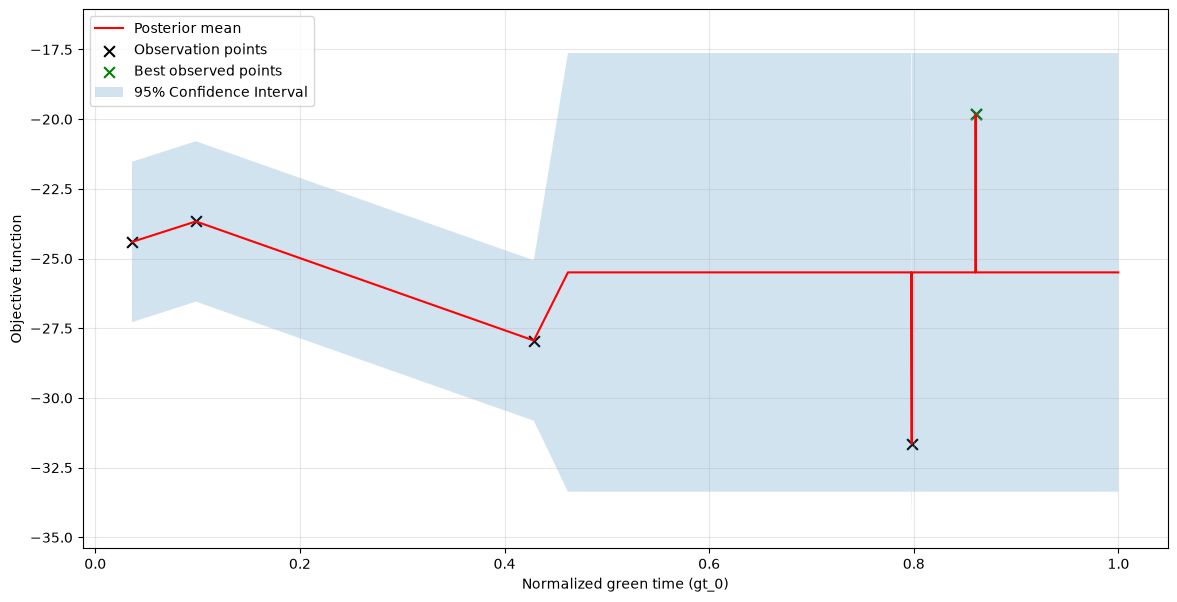

tr lb :
tensor([0.4604, 0.5753, 0.0000, 0.3930, 0.0000, 0.0000, 0.0000, 0.1095, 0.0000,
        0.0000, 0.0990, 0.0000, 0.0000, 0.0000, 0.5831, 0.2626, 0.3257, 0.0000,
        0.2164, 0.5565, 0.4530, 0.4042, 0.0000, 0.1951, 0.2781, 0.5694, 0.0987,
        0.0198, 0.1721, 0.1488, 0.1985, 0.5000, 0.0000, 0.0000, 0.2319, 0.0000,
        0.2777, 0.0000, 0.2147, 0.0386, 0.3256, 0.0000, 0.0000, 0.0000, 0.2633,
        0.0000, 0.2275, 0.0000, 0.0453, 0.5109, 0.2742, 0.5924, 0.0000, 0.0000,
        0.3751, 0.0044, 0.0000, 0.3982, 0.0000, 0.0000, 0.0000, 0.2480, 0.0360,
        0.0000, 0.3153, 0.1596, 0.0000, 0.5988, 0.1502, 0.2634, 0.1321, 0.1903,
        0.0000, 0.4608, 0.4622, 0.4691, 0.5734, 0.0000, 0.1685, 0.0000, 0.4530,
        0.3067, 0.0000, 0.0000, 0.2620, 0.0000, 0.1992, 0.0000, 0.0025, 0.0754,
        0.2049, 0.1291, 0.0000, 0.3779, 0.5233, 0.0000, 0.1583, 0.3810],
       dtype=torch.float64)
tr ub :
tensor([1.0000, 1.0000, 0.7133, 1.0000, 0.4182, 0.5997, 0.7827, 0.9095, 0.6003,
   

In [55]:
additional_xml_gt="./Ingolstadt Network/additional_gt.xml"
initial_tl_df=create_initial_tl_df(additional_xml_gt)
raw_samples=512


x_dim=98
tr_length=0.8
tr_candidates_generator=TRCandidatesGeneration(x_dim)
lower_bounds=[5]*x_dim
upper_bounds=get_upper_bounds(initial_tl_df)
dtype=torch.double
x_bounds=torch.tensor(
    [lower_bounds,
    upper_bounds],
    dtype=dtype
)
initial_length_scale_value=0.1

bo_df=pd.read_csv("./turbo_output/turbo_tr_1_iss_15_ls_0.1_tr3_q1_rs_0_training.csv")
print(bo_df.shape)
bo_df_init=bo_df[:5]
train_X= torch.from_numpy(bo_df_init[[f"gt_{i}" for i in range(x_dim)]].values)
train_X_norm = normalize(train_X,x_bounds)
train_X_norm=train_X_norm.to(dtype)
train_Y = -torch.from_numpy(bo_df_init[["loss_estimate"]].values)
train_Y=train_Y.to(dtype)

gp_model, gp_mll =initialize_gp_model(train_X=train_X_norm,train_Y=train_Y,initial_length_scale_value=initial_length_scale_value)

tr_x_norm=train_X_norm
tr_y=train_Y
tr_y_best,tr_y_best_idx=torch.max(tr_y,dim=0)
tr_x_best_norm=tr_x_norm[tr_y_best_idx.item()].clone().detach()
tr_ub=torch.clamp(tr_x_best_norm+tr_length/2,0.0,1.0)
tr_lb=torch.clamp(tr_x_best_norm-tr_length/2,0.0,1.0)


X_test=tr_candidates_generator.RAASP_sampling(
                            tr_x_best_norm,
                            tr_lb,
                            tr_ub
                            )


X_test_all=torch.concat([train_X_norm,X_test],axis=0)

posterior=gp_model.posterior(X_test_all)
fit_gpytorch_mll(gp_mll)


mean_posterior=posterior.mean.squeeze(1).detach().numpy()
var_posterior=posterior.variance.squeeze(1).detach().numpy()
std_posterior=posterior.variance.sqrt().squeeze(1).detach().numpy()

x = X_test_all[:, 0].numpy()


# Sort points according to gt_0
idx = np.argsort(x)

x = x[idx]
mean = mean_posterior[idx]
std = std_posterior[idx]

plt.figure(figsize=(14, 7))

plt.plot(x, mean, label="Posterior mean", color="red")

plt.scatter(
    train_X_norm[:, 0].numpy(),
    train_Y.numpy().flatten(),
    marker='x',
    color='black',
    s=60,
    label="Observation points"
)

plt.scatter(
    tr_x_best_norm.unsqueeze(0)[:, 0].numpy(),
    tr_y_best.numpy().flatten(),
    marker='x',
    color='green',
    s=60,
    label="Best observed points"
)

plt.fill_between(
    x,
    mean - 1.96 * std,
    mean + 1.96 * std,
    alpha=0.2,
    label="95% Confidence Interval"
)

plt.xlabel("Normalized green time (gt_0)")
plt.ylabel("Objective function")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("tr lb :")
print(tr_lb)
print("tr ub :")
print(tr_ub)
print("------------------------------")
print("Prior lengthscale :")
print(gp_model.covar_module.base_kernel.lengthscale)
print("Prior outputscale :")
print(gp_model.covar_module.outputscale)
print("Prior constant mean :")
print(gp_model.mean_module.constant)
print("---------------------------------")
print("Mean train y:")
print(train_Y.mean())
print("Var train y:")
print(train_Y.var())
print("STD train y:")
print(train_Y.std())
print("----------------------------------------")
print("Prior outputscale on original scale:")
print((gp_model.covar_module.outputscale)*train_Y.std()**2)
print("Prior constant mean on original scale:")
print(gp_model.mean_module.constant*train_Y.std()+train_Y.mean())

(5, 101)


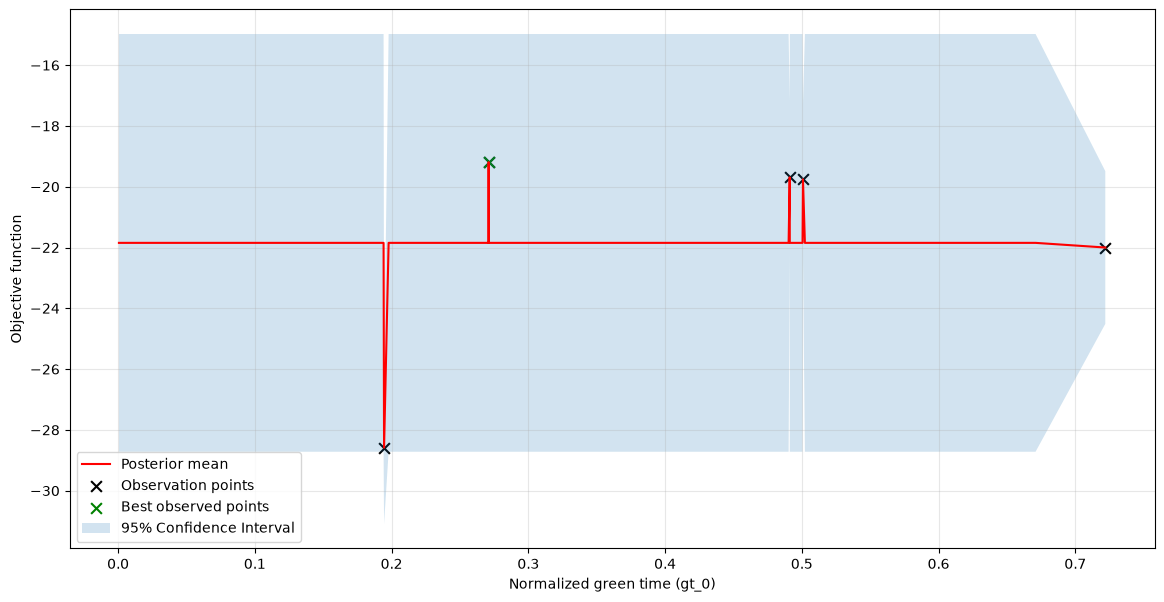

tr lb :
tensor([0.0000, 0.5101, 0.5615, 0.5571, 0.0000, 0.5640, 0.0000, 0.2901, 0.0000,
        0.4987, 0.0000, 0.1169, 0.5235, 0.1352, 0.5128, 0.0000, 0.2483, 0.5707,
        0.2371, 0.5200, 0.3230, 0.3003, 0.0636, 0.0000, 0.2241, 0.0000, 0.1640,
        0.5468, 0.0000, 0.2516, 0.2846, 0.0000, 0.0000, 0.0995, 0.4787, 0.4302,
        0.4018, 0.2999, 0.1369, 0.2677, 0.0000, 0.5603, 0.5716, 0.0399, 0.0000,
        0.0000, 0.3417, 0.0000, 0.2451, 0.0000, 0.0000, 0.4082, 0.3087, 0.3274,
        0.0000, 0.4074, 0.0065, 0.1723, 0.1423, 0.3654, 0.1314, 0.0000, 0.5720,
        0.0000, 0.4971, 0.0000, 0.0000, 0.0000, 0.0000, 0.5005, 0.2515, 0.0000,
        0.0000, 0.0000, 0.0000, 0.2448, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.5018, 0.0345, 0.0000, 0.2083, 0.5298, 0.0652, 0.1197, 0.2099, 0.4583,
        0.0797, 0.1844, 0.0000, 0.2804, 0.4152, 0.0000, 0.3362, 0.0000],
       dtype=torch.float64)
tr ub :
tensor([0.6710, 1.0000, 1.0000, 1.0000, 0.7102, 1.0000, 0.6732, 1.0000, 0.5087,
   

In [54]:
additional_xml_gt="./Ingolstadt Network/additional_gt.xml"
initial_tl_df=create_initial_tl_df(additional_xml_gt)
raw_samples=512


x_dim=98
tr_length=0.8
tr_candidates_generator=TRCandidatesGeneration(x_dim)
lower_bounds=[5]*x_dim
upper_bounds=get_upper_bounds(initial_tl_df)
dtype=torch.double
x_bounds=torch.tensor(
    [lower_bounds,
    upper_bounds],
    dtype=dtype
)
initial_length_scale_value=0.1

bo_df=pd.read_csv("./turbo_output/turbo_tr_2_iss_15_ls_0.1_tr3_q1_rs_0_training.csv")
print(bo_df.shape)
bo_df_init=bo_df[:10]
train_X= torch.from_numpy(bo_df_init[[f"gt_{i}" for i in range(x_dim)]].values)
train_X_norm = normalize(train_X,x_bounds)
train_X_norm=train_X_norm.to(dtype)
train_Y = -torch.from_numpy(bo_df_init[["loss_estimate"]].values)
train_Y=train_Y.to(dtype)

gp_model, gp_mll =initialize_gp_model(train_X=train_X_norm,train_Y=train_Y,initial_length_scale_value=initial_length_scale_value)

tr_x_norm=train_X_norm
tr_y=train_Y
tr_y_best,tr_y_best_idx=torch.max(tr_y,dim=0)
tr_x_best_norm=tr_x_norm[tr_y_best_idx.item()].clone().detach()
tr_ub=torch.clamp(tr_x_best_norm+tr_length/2,0.0,1.0)
tr_lb=torch.clamp(tr_x_best_norm-tr_length/2,0.0,1.0)


X_test=tr_candidates_generator.RAASP_sampling(
                            tr_x_best_norm,
                            tr_lb,
                            tr_ub
                            )


X_test_all=torch.concat([train_X_norm,X_test],axis=0)

posterior=gp_model.posterior(X_test_all)
fit_gpytorch_mll(gp_mll)


mean_posterior=posterior.mean.squeeze(1).detach().numpy()
var_posterior=posterior.variance.squeeze(1).detach().numpy()
std_posterior=posterior.variance.sqrt().squeeze(1).detach().numpy()

x = X_test_all[:, 0].numpy()


# Sort points according to gt_0
idx = np.argsort(x)

x = x[idx]
mean = mean_posterior[idx]
std = std_posterior[idx]

plt.figure(figsize=(14, 7))

plt.plot(x, mean, label="Posterior mean", color="red")

plt.scatter(
    train_X_norm[:, 0].numpy(),
    train_Y.numpy().flatten(),
    marker='x',
    color='black',
    s=60,
    label="Observation points"
)

plt.scatter(
    tr_x_best_norm.unsqueeze(0)[:, 0].numpy(),
    tr_y_best.numpy().flatten(),
    marker='x',
    color='green',
    s=60,
    label="Best observed points"
)

plt.fill_between(
    x,
    mean - 1.96 * std,
    mean + 1.96 * std,
    alpha=0.2,
    label="95% Confidence Interval"
)

plt.xlabel("Normalized green time (gt_0)")
plt.ylabel("Objective function")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("tr lb :")
print(tr_lb)
print("tr ub :")
print(tr_ub)
print("------------------------------")
print("Prior lengthscale :")
print(gp_model.covar_module.base_kernel.lengthscale)
print("Prior outputscale :")
print(gp_model.covar_module.outputscale)
print("Prior constant mean :")
print(gp_model.mean_module.constant)
print("---------------------------------")
print("Mean train y:")
print(train_Y.mean())
print("Var train y:")
print(train_Y.var())
print("STD train y:")
print(train_Y.std())
print("----------------------------------------")
print("Prior outputscale on original scale:")
print((gp_model.covar_module.outputscale)*train_Y.std()**2)
print("Prior constant mean on original scale:")
print(gp_model.mean_module.constant*train_Y.std()+train_Y.mean())

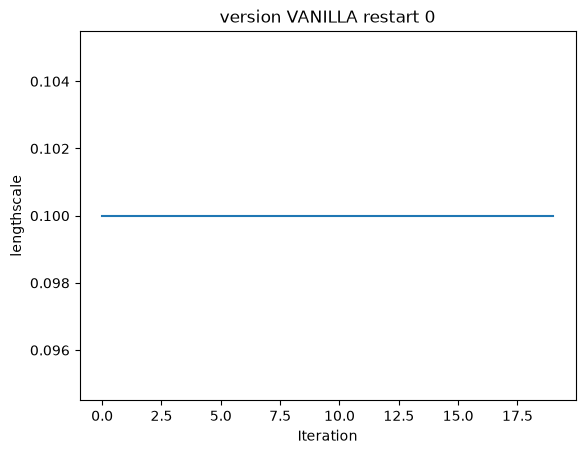

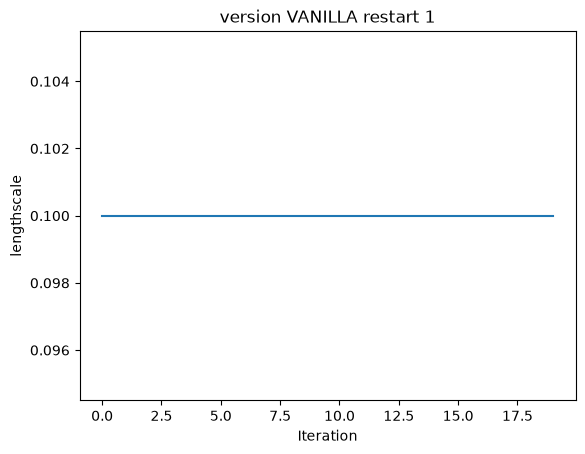

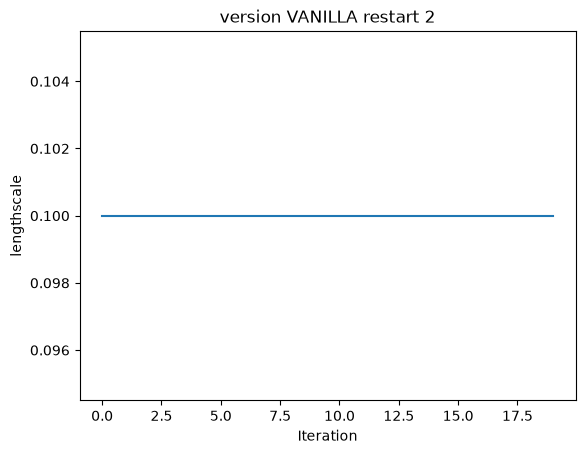

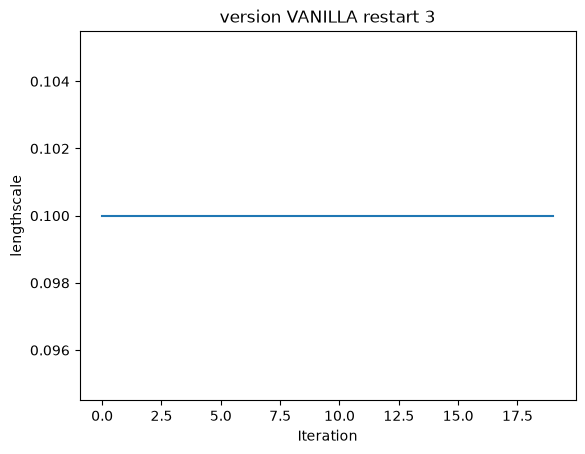

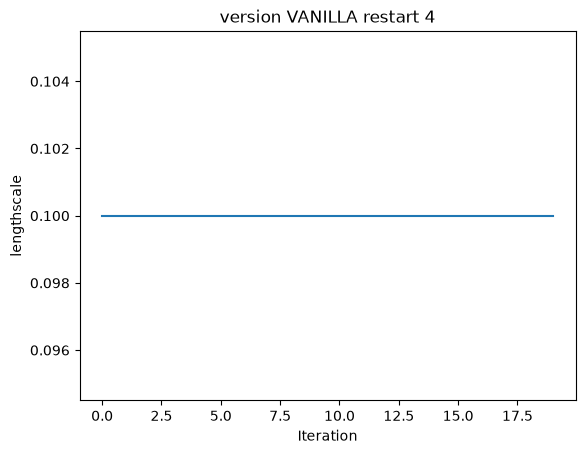

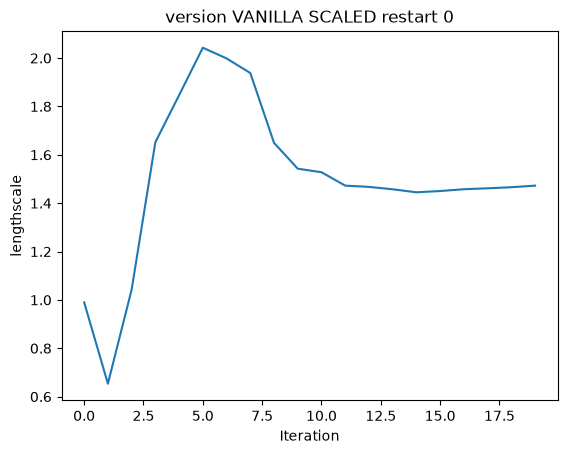

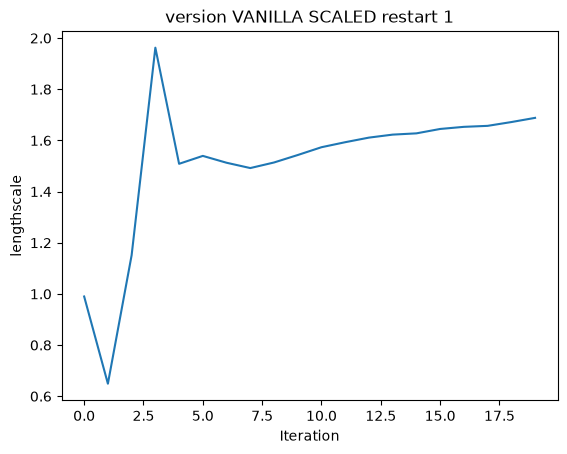

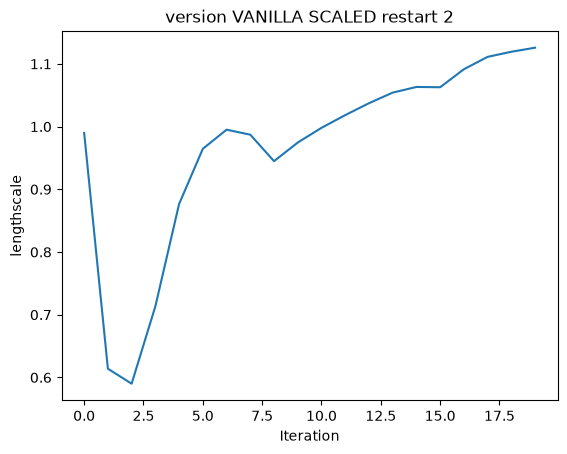

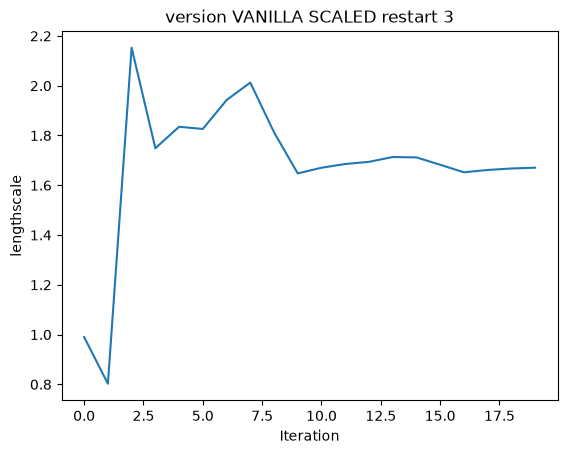

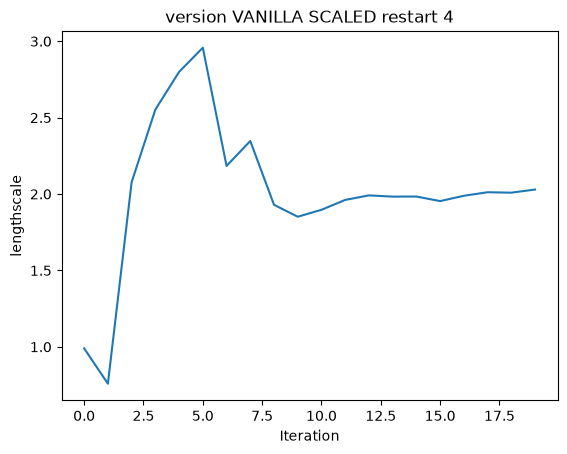

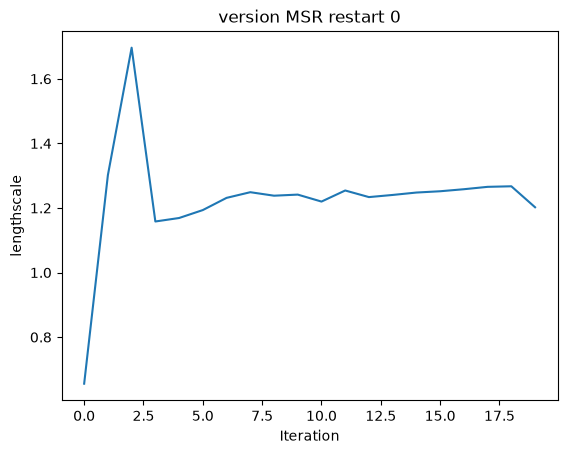

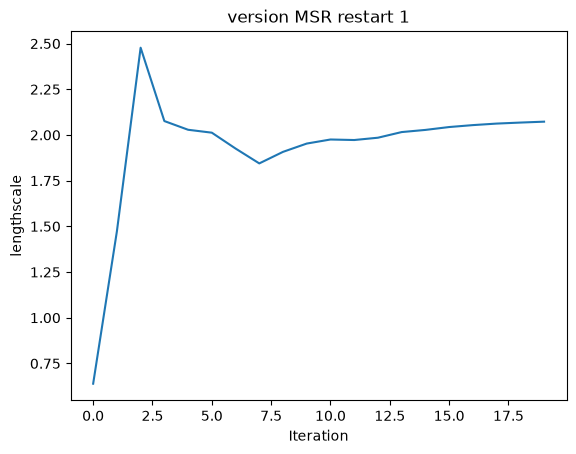

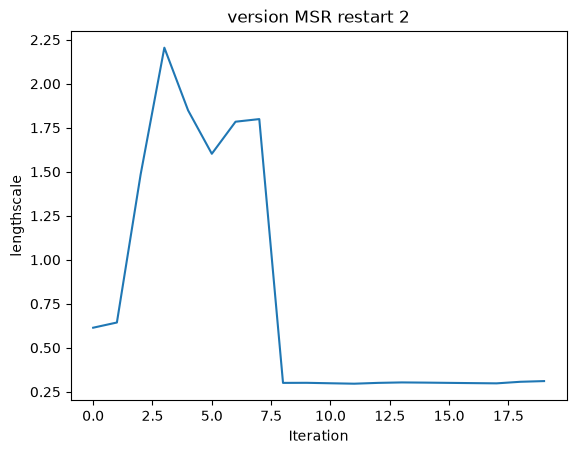

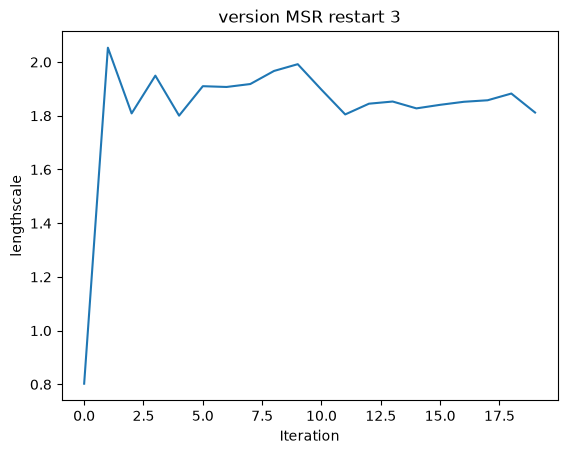

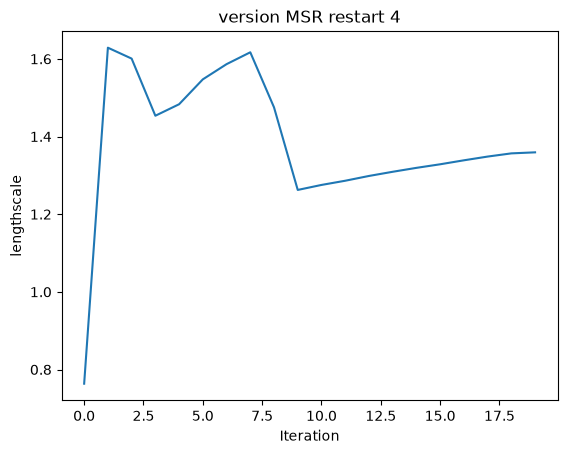

In [83]:
def hp_plot(path,method_name):
    for rs in range(5):
        hp_dict=torch.load(f"{path}{rs}.pt",weights_only=False)
        hp_dict_list=[lengthscale.detach().item() for lengthscale in hp_dict["lengthscale"]]
        plt.figure()
        plt.plot(np.arange(20),hp_dict_list[:20])
        plt.xlabel("Iteration")
        plt.ylabel("lengthscale")
        plt.title(f"version {method_name} restart {rs}")

#method_names_list=["VANILLA","MSR","TURBO"]
paths_list=[
    "./BO_output/hp_dict_VANILLA_iss_15_ls_0.1_restart",
    "./BO_output/hp_dict_VANILLA_iss_15_ls_0.1scaled_restart",
    "./BO_output/hp_dict_MSR_iss_15_ls_0.1_restart"
]

method_names_list=["VANILLA","VANILLA SCALED","MSR"]
for path,method_name in zip(paths_list,method_names_list):
    hp_plot(path,method_name)

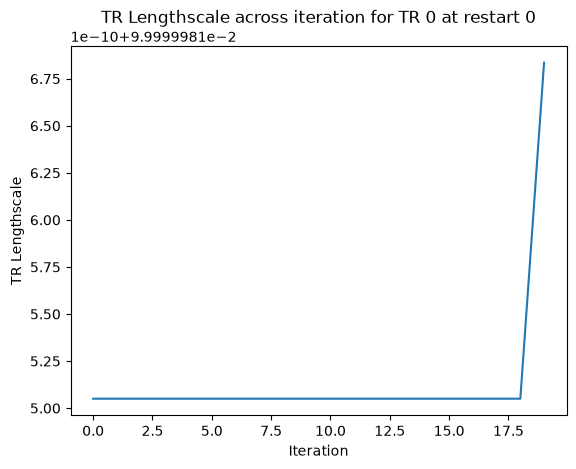

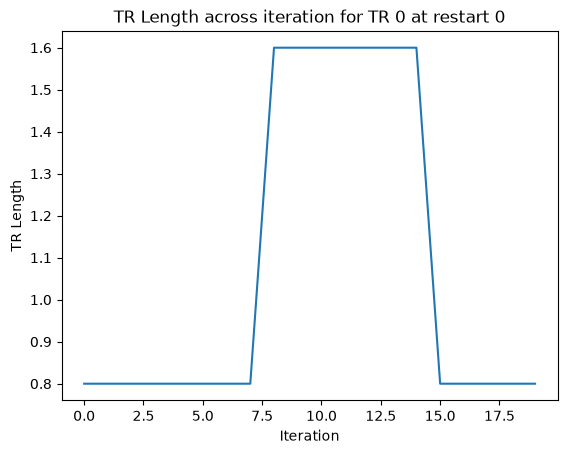

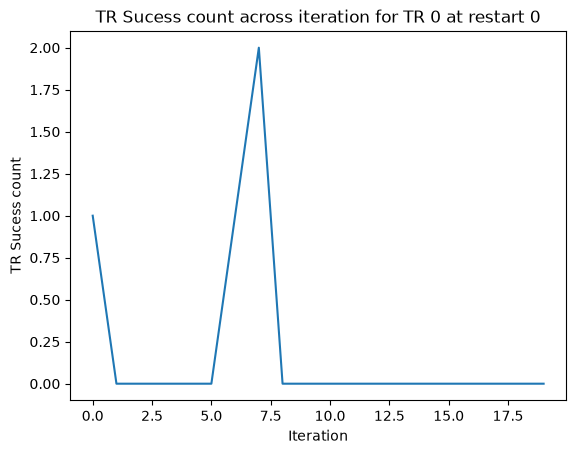

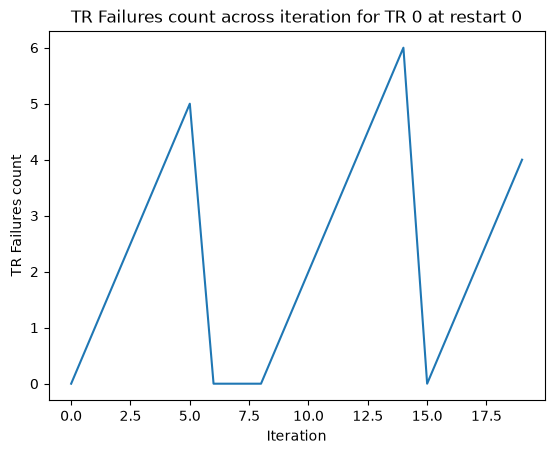

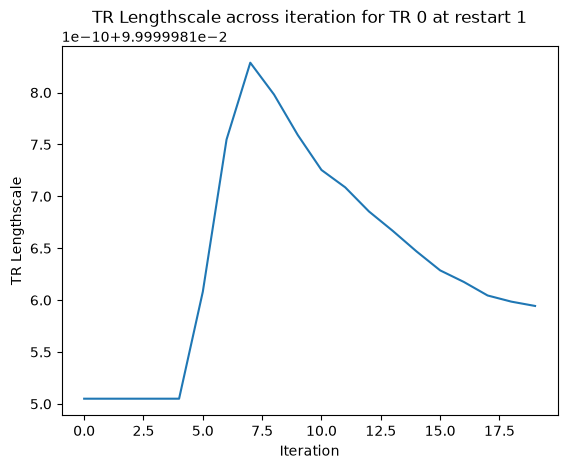

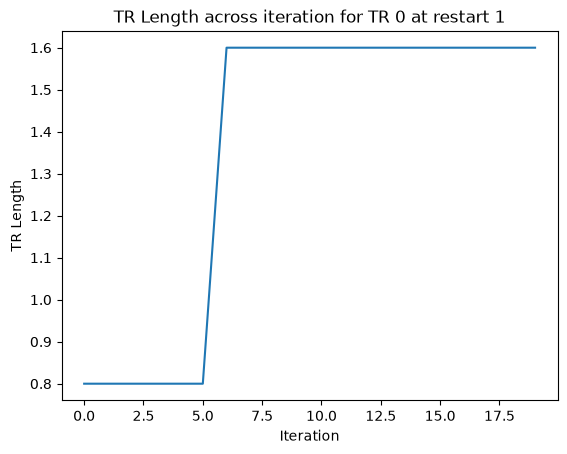

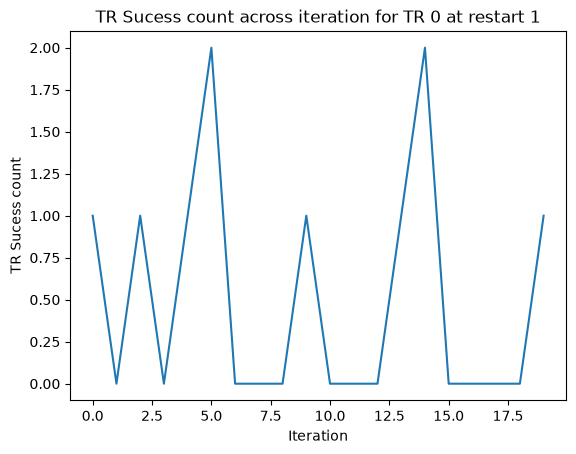

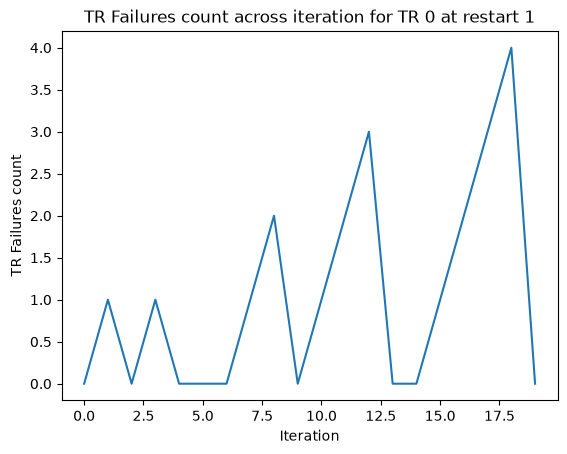

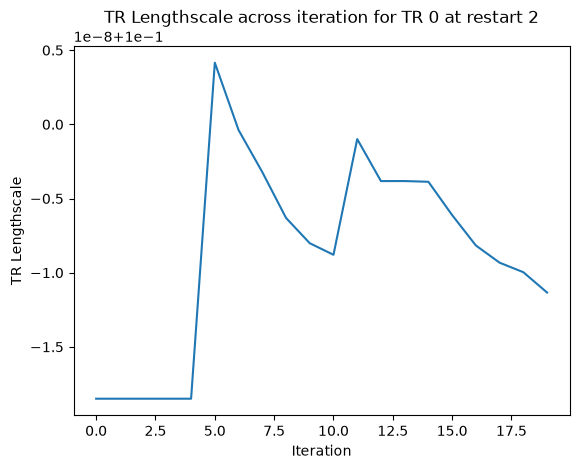

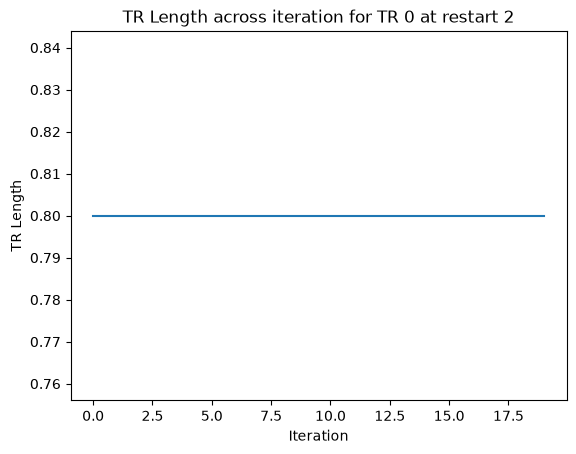

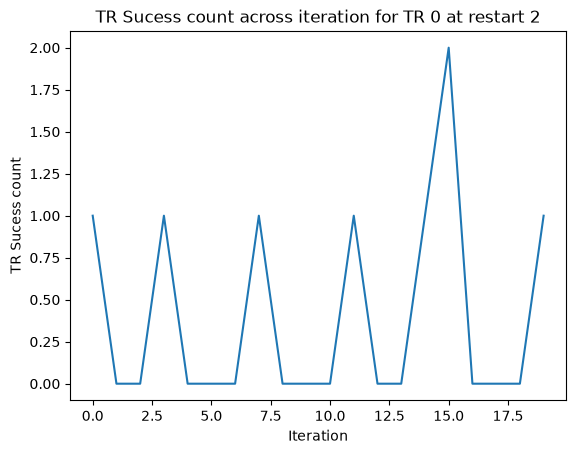

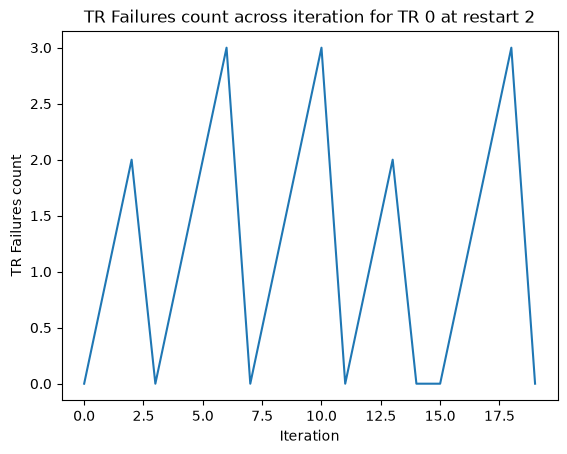

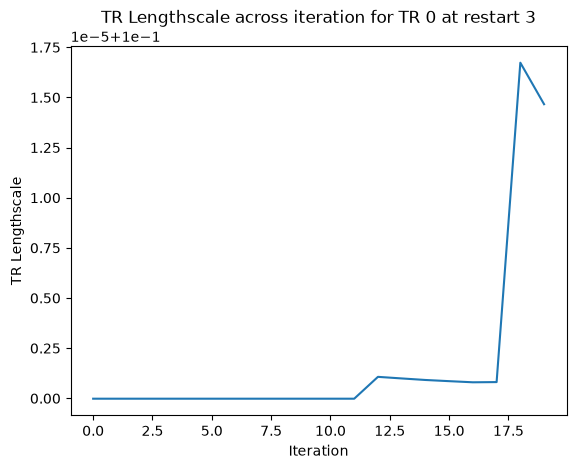

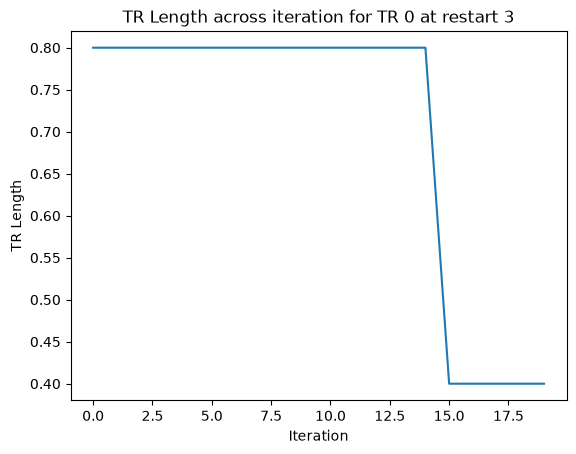

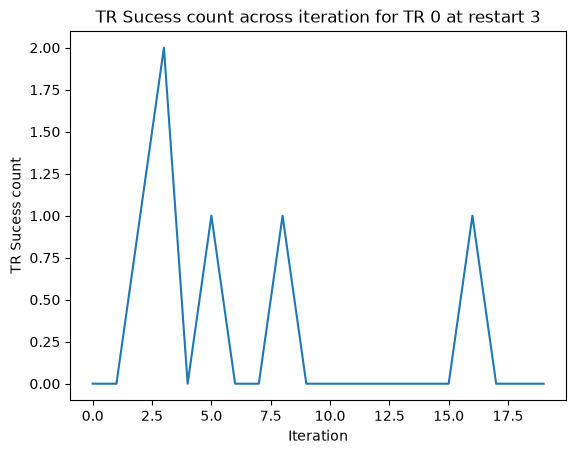

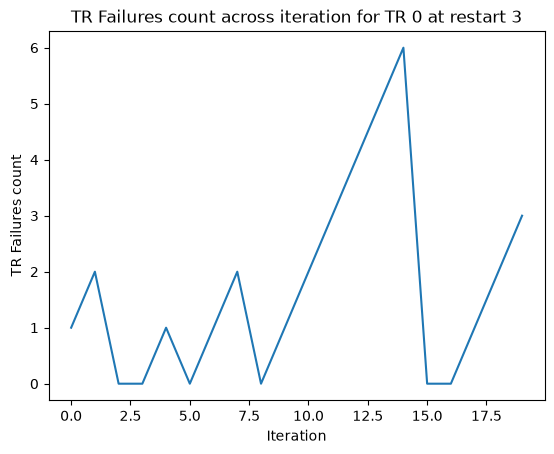

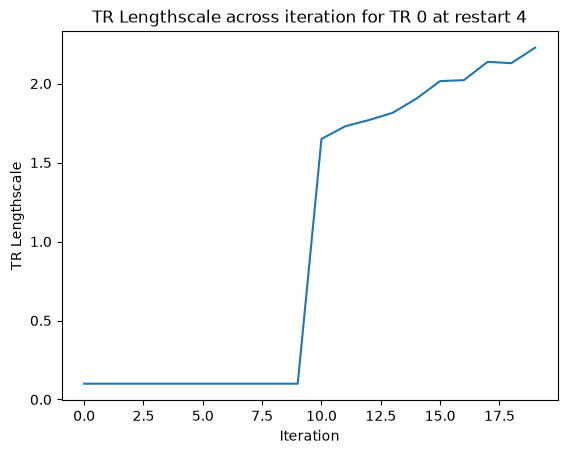

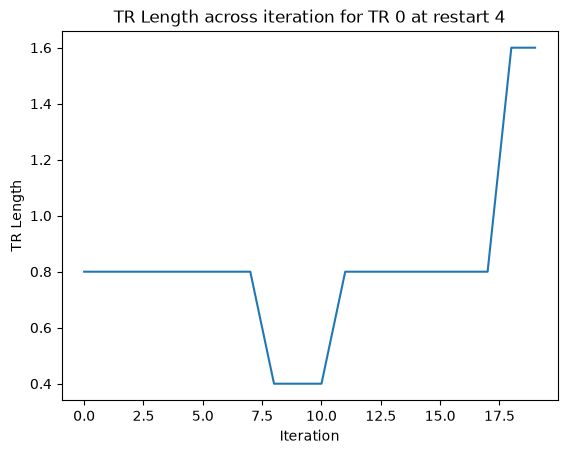

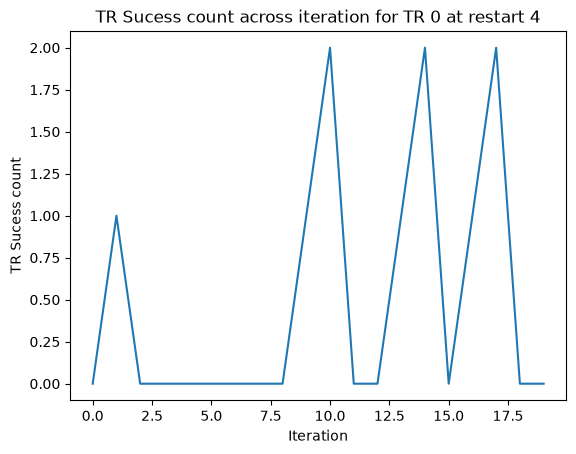

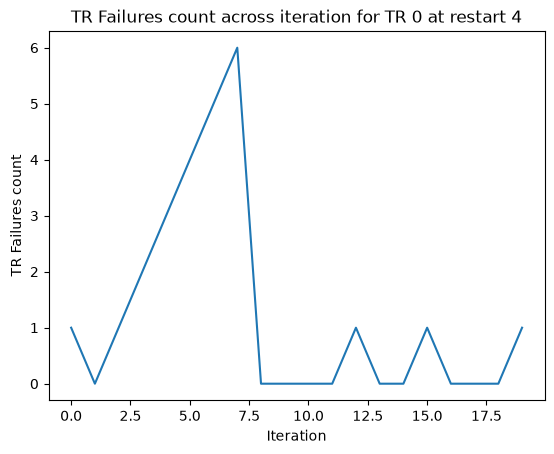

In [47]:
def tr_state_plot(n_trust_regions,annotation):
    for tr_id in range(n_trust_regions):
        for rs in range(5):
            tr_lengthscale_list=[]
            tr_success_count_list=[]
            tr_failures_count_list=[]
            tr_lengths_list=[]
            for i in range(20):
                tr_state=torch.load(f"turbo_output/tr_{tr_id}_i_{i}_{annotation}_rs_{rs}_tr_state_dict.pt",weights_only=False)
                tr_lengthscale_list.append(tr_state["tr_length_scale"].detach().item())
                tr_success_count_list.append(tr_state["tr_success_counter"])
                tr_failures_count_list.append(tr_state["tr_failure_counter"])
                tr_lengths_list.append(tr_state["tr_length"])

            plt.figure()
            plt.plot(
                np.arange(20),
                tr_lengthscale_list
            )
            plt.xlabel("Iteration")
            plt.ylabel("TR Lengthscale")
            plt.title(f"TR Lengthscale across iteration for TR {tr_id} at restart {rs}")

            plt.figure()
            plt.plot(
                np.arange(20),
                tr_lengths_list
            )
            plt.xlabel("Iteration")
            plt.ylabel("TR Length")
            plt.title(f"TR Length across iteration for TR {tr_id} at restart {rs}")

            plt.figure()
            plt.plot(
                np.arange(20),
                tr_success_count_list
            )
            plt.xlabel("Iteration")
            plt.ylabel("TR Sucess count")
            plt.title(f"TR Sucess count across iteration for TR {tr_id} at restart {rs}")

            plt.figure()
            plt.plot(
                np.arange(20),
                tr_failures_count_list
            )
            plt.xlabel("Iteration")
            plt.ylabel("TR Failures count")
            plt.title(f"TR Failures count across iteration for TR {tr_id} at restart {rs}")

tr_state_plot(1,annotation="iss_15_ls_0.1")

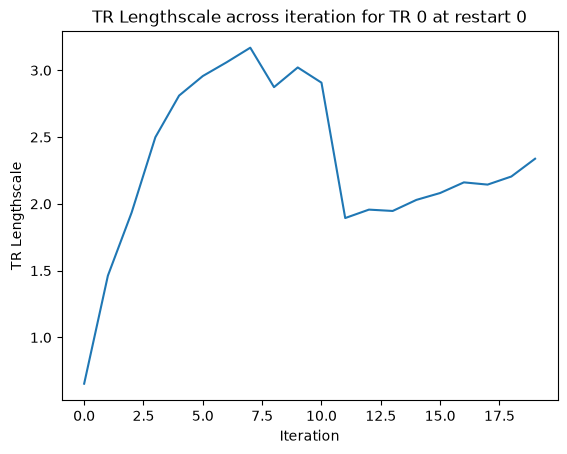

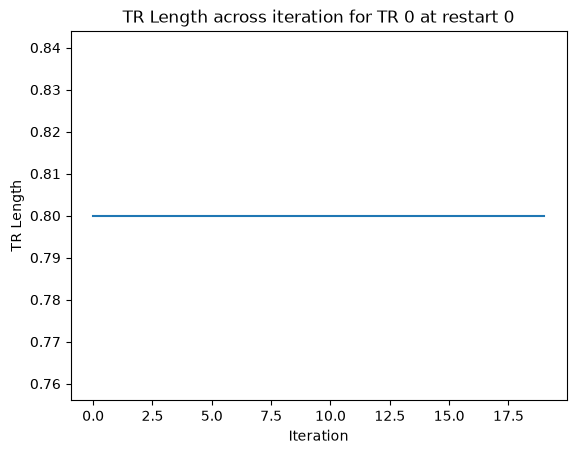

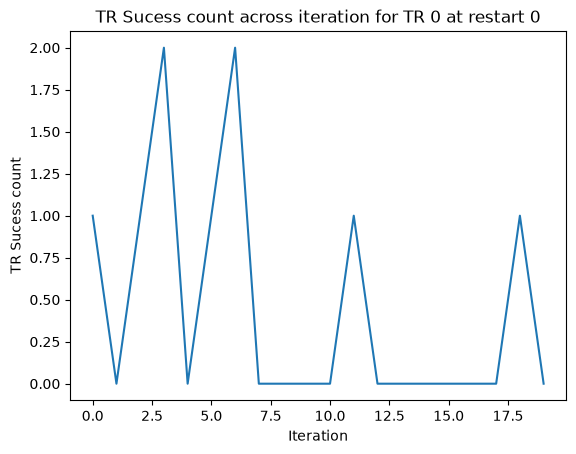

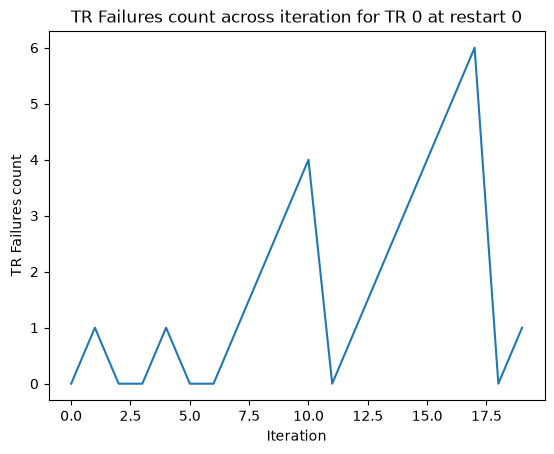

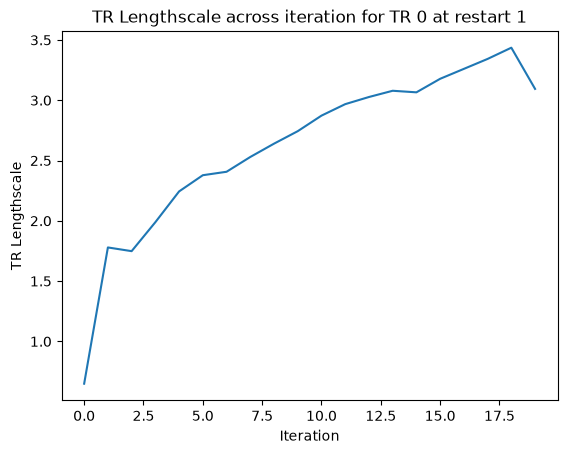

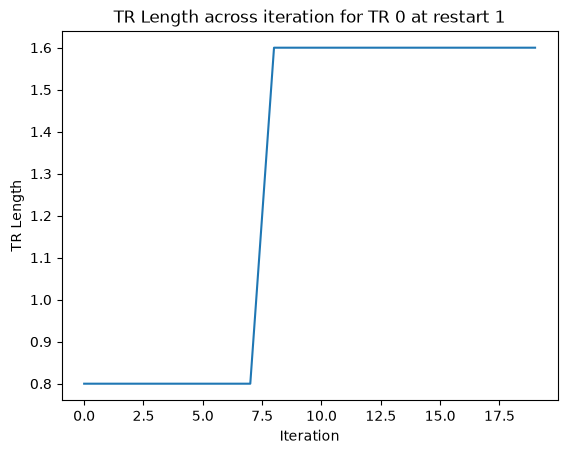

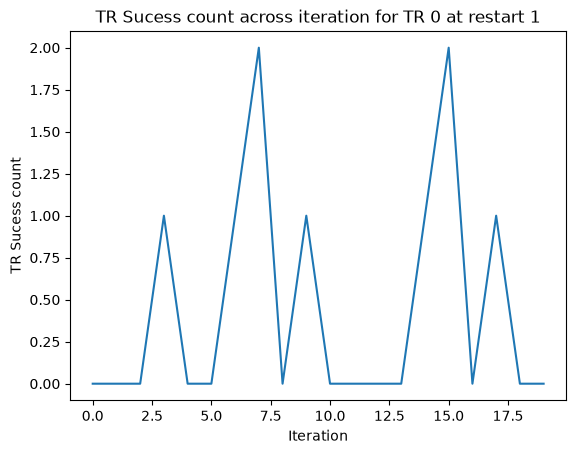

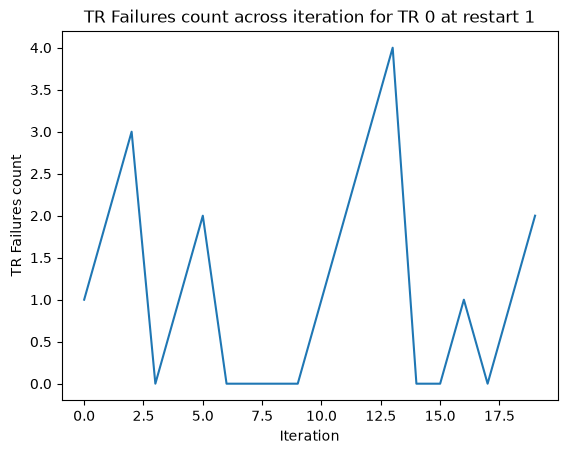

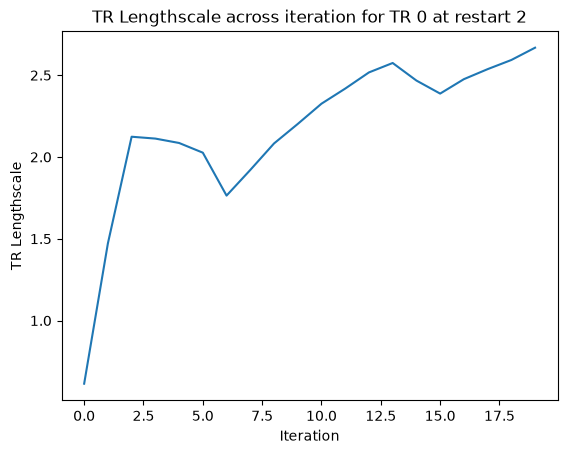

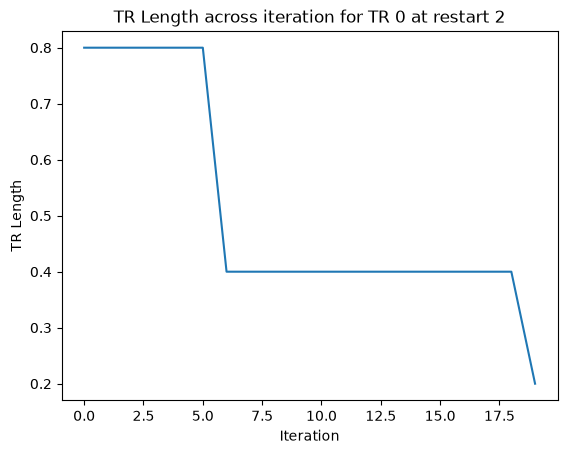

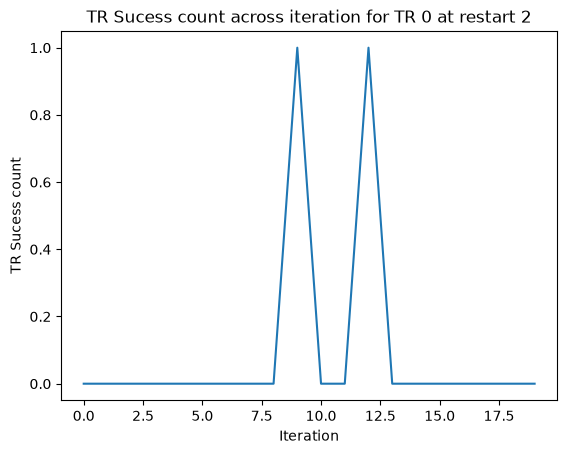

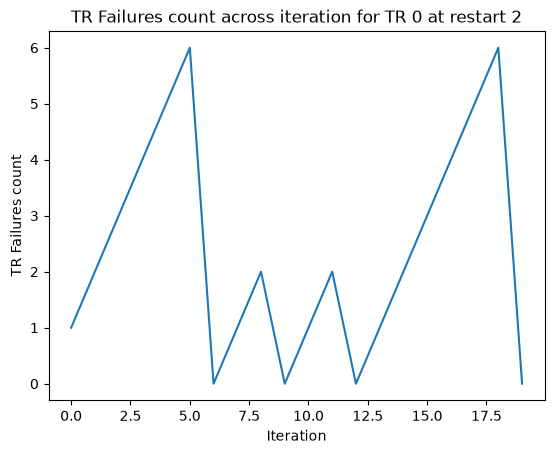

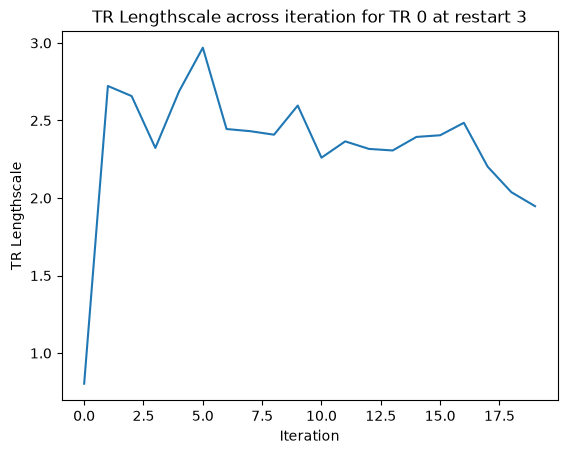

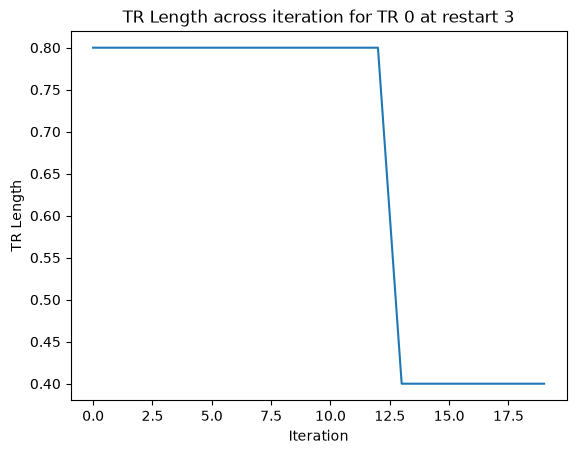

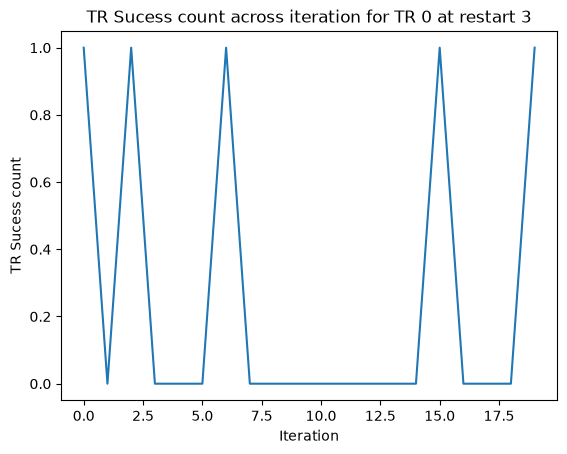

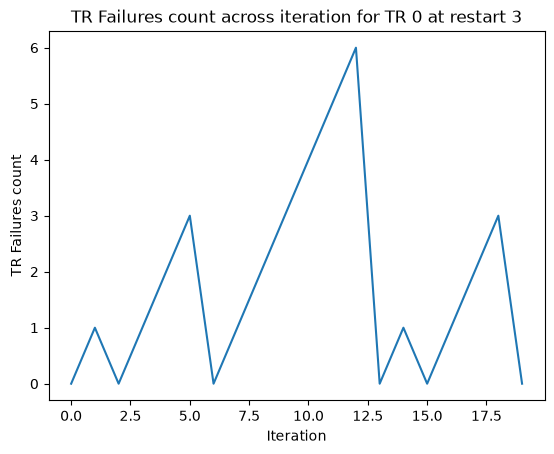

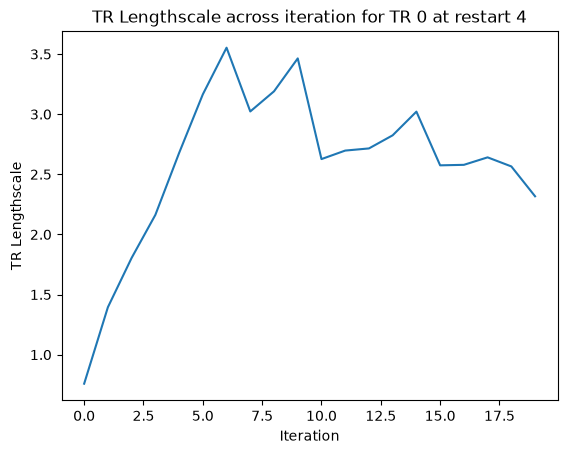

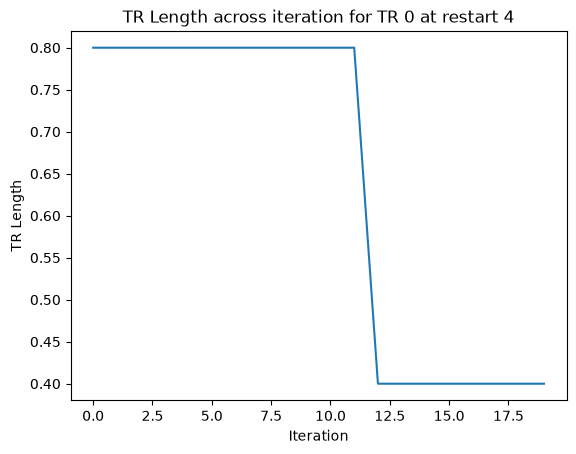

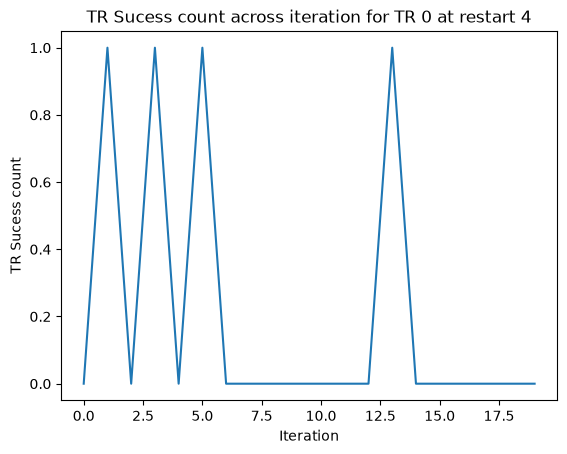

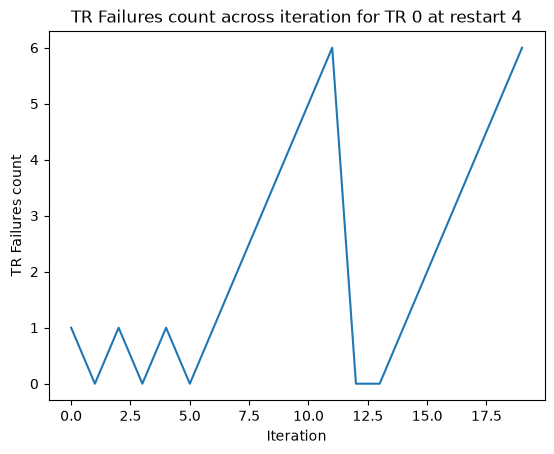

In [97]:
def tr_state_plot(n_trust_regions,annotation):
    for tr_id in range(n_trust_regions):
        for rs in range(5):
            tr_lengthscale_list=[]
            tr_success_count_list=[]
            tr_failures_count_list=[]
            tr_lengths_list=[]
            for i in range(20):
                tr_state=torch.load(f"turbo_output/tr_{tr_id}_i_{i}_{annotation}_rs_{rs}_tr_state_dict.pt",weights_only=False)
                tr_lengthscale_list.append(tr_state["tr_length_scale"].detach().item())
                tr_success_count_list.append(tr_state["tr_success_counter"])
                tr_failures_count_list.append(tr_state["tr_failure_counter"])
                tr_lengths_list.append(tr_state["tr_length"])

            plt.figure()
            plt.plot(
                np.arange(20),
                tr_lengthscale_list
            )
            plt.xlabel("Iteration")
            plt.ylabel("TR Lengthscale")
            plt.title(f"TR Lengthscale across iteration for TR {tr_id} at restart {rs}")

            plt.figure()
            plt.plot(
                np.arange(20),
                tr_lengths_list
            )
            plt.xlabel("Iteration")
            plt.ylabel("TR Length")
            plt.title(f"TR Length across iteration for TR {tr_id} at restart {rs}")

            plt.figure()
            plt.plot(
                np.arange(20),
                tr_success_count_list
            )
            plt.xlabel("Iteration")
            plt.ylabel("TR Sucess count")
            plt.title(f"TR Sucess count across iteration for TR {tr_id} at restart {rs}")

            plt.figure()
            plt.plot(
                np.arange(20),
                tr_failures_count_list
            )
            plt.xlabel("Iteration")
            plt.ylabel("TR Failures count")
            plt.title(f"TR Failures count across iteration for TR {tr_id} at restart {rs}")

tr_state_plot(1,annotation="iss_15_ls_0.1scaled")

In [1]:
import numpy as np

np.log(2)

np.float64(0.6931471805599453)